In [ ]:
# %pip install mat73

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# import mat73

Code to add to the raw dlc h5 data a new 'bodypart' named weigthed, which is the nose bodypart if its likelihood is greater than 0.3 and a weigted sum according to the likelihoods of all other bodyparts if it less than 0.3.
We then can define this bodypart in the NaviGraph to get less NaN values in the result (now we'll get Nan only for row where all values in DC where NaN)

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import scipy.io

In [2]:
folder_path = rf"C:\Maze\Video Data\\"
file_name = "NPC1_2025_08_14_13_02_08_stitched_blackedDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100_filtered"
bodyparts = ['ear_R', 'ear_L', 'midbody', 'tailbase', 'headstage']

In [3]:
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_file = pd.read_hdf(folder_path + file_name + ".h5")

In [4]:
h5_file

scorer    DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100  \
bodyparts                                                      headstage   
coords                                                                 x   
0                                                 184.620743               
1                                                 565.655945               
2                                                 565.655945               
3                                                 565.655945               
4                                                 565.585510               
...                                                      ...               
205113                                            920.325073               
205114                                            920.325073               
205115                                            921.349487               
205116                                            921.349487               
205117                                            920.256165               

scorer                                                               \
bodyparts                              ear_L                          
coords              y likelihood           x           y likelihood   
0          393.839142   0.314839  170.812988  394.578796   0.232403   
1          394.058563   0.319597  573.955994  394.748352   0.356750   
2          394.149231   0.363938  574.107788  394.748352   0.382715   
3          394.149231   0.364500  574.212891  394.646393   0.381669   
4          394.314728   0.383539  574.226379  394.646393   0.400387   
...               ...        ...         ...         ...        ...   
205113     643.516663   0.719884  912.252930  658.272095   0.830193   
205114     637.020691   0.801138  912.638367  650.762634   0.852363   
205115     628.565735   0.770397  912.654480  644.376587   0.887263   
205116     620.853638   0.803617  912.654480  634.799744   0.846309   
205117     615.786377   0.702157  912.638367  628.697876   0.931550   

scorer                                                                \
bodyparts       ear_R                            midbody               
coords              x           y likelihood           x           y   
0          171.774490  385.411896   0.374243  154.037262  384.716217   
1          569.211792  385.448029   0.353859  586.089417  384.759186   
2          569.211792  385.449982   0.383622  586.089417  384.840698   
3          569.211792  385.449982   0.371420  586.089417  384.759186   
4          569.211792  385.450958   0.375259  585.909241  384.759186   
...               ...         ...        ...         ...         ...   
205113     930.794922  659.075806   0.860223  924.302246  681.620911   
205114     930.935730  652.220642   0.782698  922.999146  676.149292   
205115     930.935730  645.722717   0.891468  922.658936  669.100037   
205116     930.794922  636.037537   0.811664  922.338501  660.033081   
205117     930.240173  632.550903   0.822218  922.242615  654.030579   

scorer                                                   
bodyparts               tailbase                         
coords    likelihood           x           y likelihood  
0           0.231249  251.394730  142.634338   0.247685  
1           0.151622  568.445007  392.507446   0.262844  
2           0.168177  568.445007  392.507446   0.272712  
3           0.165211  574.612061  472.025696   0.257550  
4           0.167901  574.576965  472.025696   0.260254  
...              ...         ...         ...        ...  
205113      0.883159  934.587463  706.189880   0.837072  
205114      0.962473  928.962402  702.176575   0.758024  
205115      0.884543  927.102539  695.640015   0.805357  
205116      0.967877  926.310486  687.683167   0.833578  
205117      0.889599  925.012817  680.774963   0.735154  

[205118 rows x 15 columns]

In [5]:
# Update to be the actual file name according to the first index column value of the h5 table
table_name = 'DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[table_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

headstage                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       184.620743  393.839142   0.314839  170.812988  394.578796   0.232403   
1       565.655945  394.058563   0.319597  573.955994  394.748352   0.356750   
2       565.655945  394.149231   0.363938  574.107788  394.748352   0.382715   
3       565.655945  394.149231   0.364500  574.212891  394.646393   0.381669   
4       565.585510  394.314728   0.383539  574.226379  394.646393   0.400387   
...            ...         ...        ...         ...         ...        ...   
205113  920.325073  643.516663   0.719884  912.252930  658.272095   0.830193   
205114  920.325073  637.020691   0.801138  912.638367  650.762634   0.852363   
205115  921.349487  628.565735   0.770397  912.654480  644.376587   0.887263   
205116  921.349487  620.853638   0.803617  912.654480  634.799744   0.846309   
205117  920.256165  615.786377   0.702157  912.638367  628.697876   0.931550   

             ear_R                            midbody                         \
                 x           y likelihood           x           y likelihood   
0       171.774490  385.411896   0.374243  154.037262  384.716217   0.231249   
1       569.211792  385.448029   0.353859  586.089417  384.759186   0.151622   
2       569.211792  385.449982   0.383622  586.089417  384.840698   0.168177   
3       569.211792  385.449982   0.371420  586.089417  384.759186   0.165211   
4       569.211792  385.450958   0.375259  585.909241  384.759186   0.167901   
...            ...         ...        ...         ...         ...        ...   
205113  930.794922  659.075806   0.860223  924.302246  681.620911   0.883159   
205114  930.935730  652.220642   0.782698  922.999146  676.149292   0.962473   
205115  930.935730  645.722717   0.891468  922.658936  669.100037   0.884543   
205116  930.794922  636.037537   0.811664  922.338501  660.033081   0.967877   
205117  930.240173  632.550903   0.822218  922.242615  654.030579   0.889599   

          tailbase                        weighted                 
                 x           y likelihood        x   y likelihood  
0       251.394730  142.634338   0.247685      NaN NaN        NaN  
1       568.445007  392.507446   0.262844      NaN NaN        NaN  
2       568.445007  392.507446   0.272712      NaN NaN        NaN  
3       574.612061  472.025696   0.257550      NaN NaN        NaN  
4       574.576965  472.025696   0.260254      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
205113  934.587463  706.189880   0.837072      NaN NaN        NaN  
205114  928.962402  702.176575   0.758024      NaN NaN        NaN  
205115  927.102539  695.640015   0.805357      NaN NaN        NaN  
205116  926.310486  687.683167   0.833578      NaN NaN        NaN  
205117  925.012817  680.774963   0.735154      NaN NaN        NaN  

[205118 rows x 18 columns]

In [7]:
from matplotlib.widgets import RectangleSelector

%matplotlib widget

coords = {}

def onselect(eclick, erelease):
    global coords
    x_min, x_max = sorted([eclick.xdata, erelease.xdata])
    y_min, y_max = sorted([eclick.ydata, erelease.ydata])
    coords['x_min'] = x_min
    coords['x_max'] = x_max
    coords['y_min'] = y_min
    coords['y_max'] = y_max
    print(f"Selected rectangle: x=({x_min:.1f}, {x_max:.1f}), y=({y_min:.1f}, {y_max:.1f})")

In [6]:
dlc_updated = dlc_raw_h5.copy()

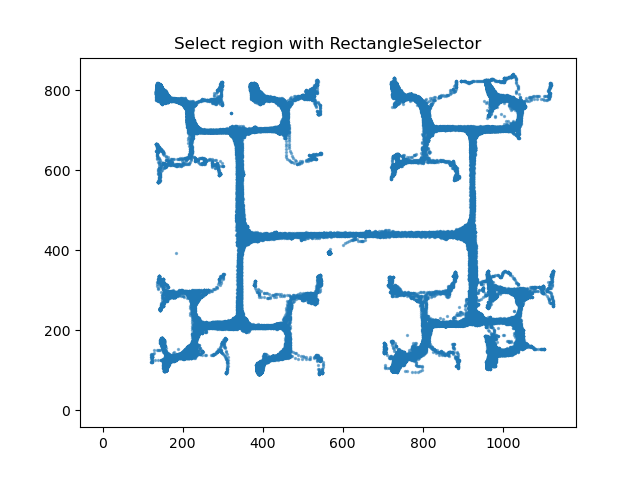

In [8]:
fig, ax = plt.subplots()
ax.scatter(dlc_updated['headstage']['x'], dlc_updated['headstage']['y'], s=2, alpha=0.5)
ax.set_title("Select region with RectangleSelector")
toggle_selector = RectangleSelector(ax, onselect, useblit=True,
                                   button=[1], minspanx=5, minspany=5, spancoords='pixels',
                                   interactive=True)
plt.show()

In [9]:
# After closing the plot, set likelihood to zero outside the selected box
def set_likelihood_to_zero_outside_boundary(df, bodypart, x_min, x_max, y_min, y_max):
    # Set likelihood to zero for rows where the bodypart is outside the bounding box
    mask = (
        (df[(bodypart, 'x')] < x_min) | (df[(bodypart, 'x')] > x_max) |
        (df[(bodypart, 'y')] < y_min) | (df[(bodypart, 'y')] > y_max)
    )
    df.loc[mask, (bodypart, 'likelihood')] = 0

if all(k in coords for k in ['x_min', 'x_max', 'y_min', 'y_max']):
    for part in bodyparts:
        set_likelihood_to_zero_outside_boundary(
            dlc_updated, part,
            coords['x_min'], coords['x_max'],
            coords['y_min'], coords['y_max']
        )
else:
    print("No rectangle was selected. Please run the cell again and select a region on the plot.")

In [10]:
# Add boolean columns 'out_of_bounds' for each bodypart and set True where coordinates are out of bounds
for bodypart in bodyparts:
    out_of_bounds_col = (bodypart, 'out_of_bounds')
    dlc_updated[out_of_bounds_col] = (
        (dlc_updated[(bodypart, 'x')] < coords['x_min']) | (dlc_updated[(bodypart, 'x')] > coords['x_max']) |
        (dlc_updated[(bodypart, 'y')] < coords['y_min']) | (dlc_updated[(bodypart, 'y')] > coords['y_max'])
    )
dlc_updated


headstage                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       184.620743  393.839142   0.314839  170.812988  394.578796   0.232403   
1       565.655945  394.058563   0.319597  573.955994  394.748352   0.356750   
2       565.655945  394.149231   0.363938  574.107788  394.748352   0.382715   
3       565.655945  394.149231   0.364500  574.212891  394.646393   0.381669   
4       565.585510  394.314728   0.383539  574.226379  394.646393   0.400387   
...            ...         ...        ...         ...         ...        ...   
205113  920.325073  643.516663   0.719884  912.252930  658.272095   0.830193   
205114  920.325073  637.020691   0.801138  912.638367  650.762634   0.852363   
205115  921.349487  628.565735   0.770397  912.654480  644.376587   0.887263   
205116  921.349487  620.853638   0.803617  912.654480  634.799744   0.846309   
205117  920.256165  615.786377   0.702157  912.638367  628.697876   0.931550   

             ear_R                            midbody  ...    tailbase  \
                 x           y likelihood           x  ...           y   
0       171.774490  385.411896   0.374243  154.037262  ...  142.634338   
1       569.211792  385.448029   0.353859  586.089417  ...  392.507446   
2       569.211792  385.449982   0.383622  586.089417  ...  392.507446   
3       569.211792  385.449982   0.371420  586.089417  ...  472.025696   
4       569.211792  385.450958   0.375259  585.909241  ...  472.025696   
...            ...         ...        ...         ...  ...         ...   
205113  930.794922  659.075806   0.860223  924.302246  ...  706.189880   
205114  930.935730  652.220642   0.782698  922.999146  ...  702.176575   
205115  930.935730  645.722717   0.891468  922.658936  ...  695.640015   
205116  930.794922  636.037537   0.811664  922.338501  ...  687.683167   
205117  930.240173  632.550903   0.822218  922.242615  ...  680.774963   

                  weighted                        ear_R         ear_L  \
       likelihood        x   y likelihood out_of_bounds out_of_bounds   
0        0.247685      NaN NaN        NaN         False         False   
1        0.262844      NaN NaN        NaN         False         False   
2        0.272712      NaN NaN        NaN         False         False   
3        0.257550      NaN NaN        NaN         False         False   
4        0.260254      NaN NaN        NaN         False         False   
...           ...      ...  ..        ...           ...           ...   
205113   0.837072      NaN NaN        NaN         False         False   
205114   0.758024      NaN NaN        NaN         False         False   
205115   0.805357      NaN NaN        NaN         False         False   
205116   0.833578      NaN NaN        NaN         False         False   
205117   0.735154      NaN NaN        NaN         False         False   

             midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds  
0              False         False         False  
1              False         False         False  
2              False         False         False  
3              False         False         False  
4              False         False         False  
...              ...           ...           ...  
205113         False         False         False  
205114         False         False         False  
205115         False         False         False  
205116         False         False         False  
205117         False         False         False  

[205118 rows x 23 columns]

In [275]:
for bodypart in bodyparts:
    set_likelihood_to_zero_outside_boundary(dlc_updated, bodypart, coords['x_min'], coords['x_max'], coords['y_min'], coords['y_max'])

In [11]:
coords

{'x_min': 93.53605976719996,
 'x_max': 1139.9139710949314,
 'y_min': 73.45963058471682,
 'y_max': 858.0284742446175}

In [12]:
N = 5
# Find the first index with N consecutive rows where all bodyparts have likelihood > 0
start_count = 0
start_zeros = 0
for i in range(len(dlc_updated)):
    if all(dlc_updated.loc[i, (bp, 'likelihood')] > 0 for bp in bodyparts):
        start_count += 1
        if start_count >= N:
            break
    else:
        start_count = 0
        start_zeros = i + 1  # index after the last zero row

# Find the last index with N consecutive rows where all bodyparts have likelihood > 0
end_count = 0
end_zeros = 0
for j in range(len(dlc_updated) - 1, -1, -1):
    if all(dlc_updated.loc[j, (bp, 'likelihood')] > 0 for bp in bodyparts):
        end_count += 1
        if end_count >= N:
            break
    else:
        end_count = 0
        end_zeros = len(dlc_updated) - j  # number of rows to drop from the end

print(f"Start zeros to drop: {start_zeros}, End zeros to drop: {end_zeros}")
# Drop the rows at the beginning and end
# dlc_updated = dlc_updated.iloc[start_zeros:len(dlc_updated)-end_zeros].reset_index(drop=True)

Start zeros to drop: 0, End zeros to drop: 0


In [ ]:
for bodypart in bodyparts:
    fixed_count = 0
    total_out_of_bounds = 0

    for i in range(len(dlc_updated)):
        if dlc_updated.loc[i, (bodypart, 'out_of_bounds')] == True:
            total_out_of_bounds += 1
            prev_idx = None
            next_idx = None
            # Search for previous frame with nonzero likelihood
            for offset in range(1, 30):
                idx = i - offset
                if idx >= 0 and dlc_updated.loc[idx, (bodypart, 'out_of_bounds')] == False:
                    prev_idx = idx
                    break
            # Search for next frame with nonzero likelihood
            for offset in range(1, 30):
                idx = i + offset
                if idx < len(dlc_updated) and dlc_updated.loc[idx, (bodypart, 'out_of_bounds')] == False:
                    next_idx = idx
                    break
            # If both found, interpolate
            if prev_idx is not None and next_idx is not None:
                x_val = (dlc_updated.loc[prev_idx, (bodypart, 'x')] + dlc_updated.loc[next_idx, (bodypart, 'x')]) / 2
                y_val = (dlc_updated.loc[prev_idx, (bodypart, 'y')] + dlc_updated.loc[next_idx, (bodypart, 'y')]) / 2
                likelihood_val = (dlc_updated.loc[prev_idx, (bodypart, 'likelihood')] + dlc_updated.loc[next_idx, (bodypart, 'likelihood')]) / 2

                dlc_updated.loc[i, (bodypart, 'x')] = x_val
                dlc_updated.loc[i, (bodypart, 'y')] = y_val
                dlc_updated.loc[i, (bodypart, 'likelihood')] = likelihood_val
                fixed_count += 1

    print(f"{bodypart}: Total out-of-bounds rows: {total_out_of_bounds}")
    print(f"{bodypart}: Rows fixed by interpolation: {fixed_count}")

ear_R: Total out-of-bounds rows: 5004
ear_R: Rows fixed by interpolation: 4781
ear_L: Total out-of-bounds rows: 2825
ear_L: Rows fixed by interpolation: 2641
midbody: Total out-of-bounds rows: 1234
midbody: Rows fixed by interpolation: 1015
tailbase: Total out-of-bounds rows: 11026
tailbase: Rows fixed by interpolation: 9117
headstage: Total out-of-bounds rows: 9780
headstage: Rows fixed by interpolation: 9260


In [13]:
dlc_updated_polynomial = dlc_updated.copy()

for bodypart in bodyparts:
    fixed_count = 0
    total_out_of_bounds = 0

    for i in range(len(dlc_updated_polynomial)):
        if dlc_updated_polynomial.loc[i, (bodypart, 'out_of_bounds')] == True:
            total_out_of_bounds += 1

            # Find up to 2 previous and 2 next valid indices for polynomial fit
            prev_valid = []
            next_valid = []
            for offset in range(1, 30):
                idx = i - offset
                if idx >= 0 and dlc_updated_polynomial.loc[idx, (bodypart, 'out_of_bounds')] == False:
                    prev_valid.append(idx)
                    if len(prev_valid) == 2:
                        break
            for offset in range(1, 30):
                idx = i + offset
                if idx < len(dlc_updated_polynomial) and dlc_updated_polynomial.loc[idx, (bodypart, 'out_of_bounds')] == False:
                    next_valid.append(idx)
                    if len(next_valid) == 2:
                        break

            valid_indices = prev_valid[::-1] + next_valid  # reverse prev_valid to chronological order
            if len(valid_indices) >= 3:  # Need at least 3 points for quadratic
                xs = [dlc_updated_polynomial.loc[idx, (bodypart, 'x')] for idx in valid_indices]
                ys = [dlc_updated_polynomial.loc[idx, (bodypart, 'y')] for idx in valid_indices]
                ls = [dlc_updated_polynomial.loc[idx, (bodypart, 'likelihood')] for idx in valid_indices]
                frame_indices = valid_indices

                # Fit polynomial for x and y
                poly_x = np.polyfit(frame_indices, xs, 2)
                poly_y = np.polyfit(frame_indices, ys, 2)
                poly_l = np.polyfit(frame_indices, ls, 2)

                dlc_updated_polynomial.loc[i, (bodypart, 'x')] = np.polyval(poly_x, i)
                dlc_updated_polynomial.loc[i, (bodypart, 'y')] = np.polyval(poly_y, i)
                dlc_updated_polynomial.loc[i, (bodypart, 'likelihood')] = np.polyval(poly_l, i)
                fixed_count += 1

    print(f"{bodypart}: Total out-of-bounds rows: {total_out_of_bounds}")
    print(f"{bodypart}: Rows fixed by polynomial interpolation: {fixed_count}")

ear_R: Total out-of-bounds rows: 0
ear_R: Rows fixed by polynomial interpolation: 0
ear_L: Total out-of-bounds rows: 0
ear_L: Rows fixed by polynomial interpolation: 0
midbody: Total out-of-bounds rows: 0
midbody: Rows fixed by polynomial interpolation: 0
tailbase: Total out-of-bounds rows: 0
tailbase: Rows fixed by polynomial interpolation: 0
headstage: Total out-of-bounds rows: 0
headstage: Rows fixed by polynomial interpolation: 0


In [ ]:
import os
from matplotlib.collections import LineCollection

def plot_compare_interpolations(
    dlc_linear, dlc_poly, trial_times_maze, save_dir, maze_img, bodypart='headstage', fps=40, cmap='viridis'
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    fixed_linear = dlc_linear[bodypart]['out_of_bounds']
    fixed_poly = dlc_poly[bodypart]['out_of_bounds']

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_lin = dlc_linear[bodypart]['x'][start_idx:end_idx].values
        y_lin = dlc_linear[bodypart]['y'][start_idx:end_idx].values
        x_poly = dlc_poly[bodypart]['x'][start_idx:end_idx].values
        y_poly = dlc_poly[bodypart]['y'][start_idx:end_idx].values

        fixed_lin_trial = fixed_linear[start_idx:end_idx].values
        fixed_poly_trial = fixed_poly[start_idx:end_idx].values

        frames = np.arange(start_idx, end_idx)
        # Prepare segments for LineCollection
        points_lin = np.array([x_lin, y_lin]).T.reshape(-1, 1, 2)
        segments_lin = np.concatenate([points_lin[:-1], points_lin[1:]], axis=1)
        points_poly = np.array([x_poly, y_poly]).T.reshape(-1, 1, 2)
        segments_poly = np.concatenate([points_poly[:-1], points_poly[1:]], axis=1)

        fig, axes = plt.subplots(1, 2, figsize=(18, 9))

        # Linear interpolation plot
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_lin = LineCollection(segments_lin, cmap=cmap)
        lc_lin.set_array(frames[:-1])
        lc_lin.set_linewidth(1)
        axes[0].add_collection(lc_lin)
        if fixed_lin_trial.any():
            axes[0].scatter(x_lin[fixed_lin_trial], y_lin[fixed_lin_trial], color='red', s=8, label='Fixed (Linear)')
        axes[0].set_title(f'Trial {i+1} (Linear Interpolation)')
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)
        plt.colorbar(lc_lin, ax=axes[0], label='Frame')
        axes[0].legend(loc='upper right', fontsize=8)

        # Polynomial interpolation plot
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_poly = LineCollection(segments_poly, cmap=cmap)
        lc_poly.set_array(frames[:-1])
        lc_poly.set_linewidth(1)
        axes[1].add_collection(lc_poly)
        if fixed_poly_trial.any():
            axes[1].scatter(x_poly[fixed_poly_trial], y_poly[fixed_poly_trial], color='orange', s=8, label='Fixed (Poly)')
        axes[1].set_title(f'Trial {i+1} (Polynomial Interpolation)')
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)
        plt.colorbar(lc_poly, ax=axes[1], label='Frame')
        axes[1].legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_compare_jumps_poly.png"))
        plt.close(fig)

# Example usage:
plot_compare_interpolations(
    dlc_updated, dlc_updated_polynomial, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_compare_jumps_poly",
    maze_image,
    bodypart='headstage'
)

In [14]:
trial_info = scipy.io.loadmat(r"C:\Users\Almog\Downloads\NPC1_14082025_1_trial_info.mat")
trial_times = trial_info['trial_info'][0][0][0]

In [15]:
trial_times_maze = trial_times[31:-31] - 2
trial_times_maze

array([[11.8051    ],
       [ 4.14196667],
       [ 4.2557    ],
       [ 4.30603333],
       [ 6.13766667],
       [ 2.658     ],
       [ 4.56676667],
       [10.67326667],
       [ 4.23813333],
       [ 4.72843333],
       [ 5.00213333],
       [ 6.97836667],
       [10.88176667],
       [ 2.41616667],
       [ 6.25536667],
       [ 4.23683333],
       [ 4.2932    ],
       [ 4.51456667],
       [ 4.24313333],
       [ 9.53536667],
       [ 4.20433333],
       [16.5619    ],
       [ 6.01693333],
       [14.72616667],
       [ 4.46593333],
       [ 3.68743333],
       [ 4.34553333],
       [ 4.31746667],
       [ 5.31726667],
       [ 3.58546667],
       [ 2.23306667],
       [ 6.66956667],
       [ 7.10143333],
       [ 4.22896667],
       [ 4.22076667],
       [ 4.26836667],
       [ 4.6369    ],
       [ 3.37093333],
       [ 2.72493333],
       [ 4.23133333],
       [ 4.47563333],
       [ 4.37173333],
       [ 4.20973333],
       [ 2.18953333],
       [ 2.83683333],
       [ 4

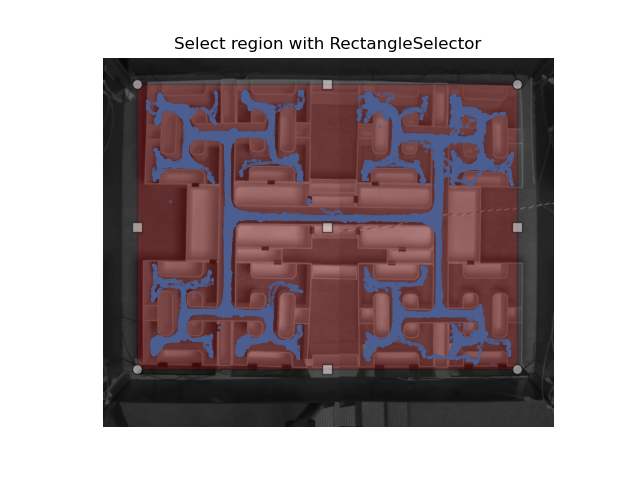

In [17]:
maze_video_path = r"C:\Maze\Video Data\NPC1_2025_08_14_13_02_08_stitched_blacked.mp4"
#Extract image from video
import cv2
cap = cv2.VideoCapture(maze_video_path)
ret, frame = cap.read()
if ret:
    maze_image = frame
cap.release()

# plot the maze image
plt.imshow(cv2.cvtColor(maze_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [27]:
dlc_jumps = dlc_updated.copy()

def fix_jumps_in_maze(dlc_df, bodyparts, N=5, percentile=99.9):
    for bp in bodyparts:
        print(f"\nProcessing bodypart: {bp}")
        x = dlc_df[(bp, 'x')].values
        y = dlc_df[(bp, 'y')].values

        dx = np.diff(x)
        dy = np.diff(y)
        movement = np.sqrt(dx**2 + dy**2)

        if len(movement) == 0:
            print("No valid movement data for this bodypart.")
            continue
        jump_thresh = np.percentile(movement, percentile)
        print(f"Jump threshold (percentile {percentile}): {jump_thresh:.2f}")

        i = 0
        outlier_count = 0
        while i < len(x) - 1:
            dist = np.sqrt((x[i+1] - x[i])**2 + (y[i+1] - y[i])**2)
            if dist > jump_thresh:
                # Look ahead to see if the next frame also exceeds threshold
                seq_indices = [i]
                valid_seq = [i]
                j = i + 2
                while j < len(x) - 1 and np.sqrt((x[j] - x[j-1])**2 + (y[j] - y[j-1])**2) > jump_thresh:
                    valid_seq.append(j)
                    j += 2
                    print(f"  Jump continues at frame {j}")
                if len(valid_seq) >= 2:
                    print(f"  Multiple jumps detected at frames {valid_seq}")
                    # Interpolate invalid frames between valid indices in valid_seq
                    for idx in range(len(valid_seq) - 1):
                        start_idx = valid_seq[idx]
                        end_idx = valid_seq[idx + 1]
                        # Interpolate for frames between start_idx and end_idx (exclusive)
                        for k in range(start_idx + 1, end_idx):
                            print(f"  Interpolating from {start_idx} to {end_idx} (frame {k})")
                            alpha = (k - start_idx) / (end_idx - start_idx)
                            new_x = (1 - alpha) * x[start_idx] + alpha * x[end_idx]
                            new_y = (1 - alpha) * y[start_idx] + alpha * y[end_idx]
                            dlc_df.loc[k, (bp, 'x')] = new_x
                            dlc_df.loc[k, (bp, 'y')] = new_y
                        outlier_count += 1
                    i = end_idx
                    continue
                else:
                    # --- Normal jump case ---
                    jump_indices = []
                    j = i + 1
                    while j < len(x) and (j - i) <= N:
                        jump_indices.append(j)
                        j += 1
                    if len(jump_indices) > 0 and j < len(x):
                        print(f"  Interpolating from {i} to {j} (invalids: {jump_indices})")
                        for k in jump_indices:
                            alpha = (k - i) / (j - i)
                            new_x = (1 - alpha) * x[i] + alpha * x[j]
                            new_y = (1 - alpha) * y[i] + alpha * y[j]
                            print(f"    Frame {k}: x={dlc_df.loc[k, (bp, 'x')]:.2f}->{new_x:.2f}, y={dlc_df.loc[k, (bp, 'y')]:.2f}->{new_y:.2f}")
                            dlc_df.loc[k, (bp, 'x')] = new_x
                            dlc_df.loc[k, (bp, 'y')] = new_y
                            outlier_count += 1
                        i = j
                        continue
            i += 1
        print(f"Total outliers fixed for {bp}: {outlier_count}")

# Usage:
fix_jumps_in_maze(dlc_jumps, bodyparts, N=20, percentile=99.9)


Processing bodypart: ear_R
Jump threshold (percentile 99.9): 63.96
  Interpolating from 0 to 21 (invalids: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20])
    Frame 1: x=569.21->190.72, y=385.45->385.45
    Frame 2: x=569.21->209.67, y=385.45->385.48
    Frame 3: x=569.21->228.61, y=385.45->385.51
    Frame 4: x=569.21->247.56, y=385.45->385.55
    Frame 5: x=569.21->266.51, y=385.60->385.58
    Frame 6: x=569.32->285.45, y=385.64->385.62
    Frame 7: x=569.36->304.40, y=385.65->385.65
    Frame 8: x=569.38->323.35, y=385.65->385.69
    Frame 9: x=569.44->342.29, y=385.65->385.72
    Frame 10: x=569.44->361.24, y=385.65->385.75
    Frame 11: x=569.48->380.19, y=385.66->385.79
    Frame 12: x=569.49->399.13, y=385.69->385.82
    Frame 13: x=569.48->418.08, y=385.69->385.86
    Frame 14: x=569.48->437.03, y=385.74->385.89
    Frame 15: x=569.48->455.97, y=385.84->385.93
    Frame 16: x=569.48->474.92, y=385.85->385.96
    Frame 17: x=569.48->493.87, y=385.86->38

C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '190.72108096168154' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = new_x
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:64: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '385.4461611793154' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = new_y


    Frame 41221: x=908.08->902.97, y=231.66->233.51
    Frame 41222: x=909.28->904.24, y=233.59->233.74
    Frame 41223: x=910.97->905.50, y=234.89->233.98
    Frame 41224: x=910.97->906.76, y=234.91->234.21
    Frame 41225: x=910.97->908.03, y=234.95->234.44
    Frame 41226: x=910.55->909.29, y=234.91->234.68
  Interpolating from 41233 to 41254 (invalids: [41234, 41235, 41236, 41237, 41238, 41239, 41240, 41241, 41242, 41243, 41244, 41245, 41246, 41247, 41248, 41249, 41250, 41251, 41252, 41253])
    Frame 41234: x=569.83->907.48, y=385.49->232.90
    Frame 41235: x=569.80->906.20, y=385.49->232.42
    Frame 41236: x=569.80->904.92, y=385.49->231.93
    Frame 41237: x=569.80->903.64, y=385.49->231.44
    Frame 41238: x=569.83->902.37, y=385.49->230.95
    Frame 41239: x=569.84->901.09, y=385.46->230.46
    Frame 41240: x=569.85->899.81, y=385.45->229.97
    Frame 41241: x=569.85->898.53, y=385.45->229.49
    Frame 41242: x=898.19->897.26, y=231.33->229.00
    Frame 41243: x=898.19->895.

C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '190.01941789899553' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = new_x
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:64: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '394.5779622395833' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = new_y


    Frame 2: x=574.11->209.23, y=394.75->394.58
    Frame 3: x=574.21->228.43, y=394.65->394.58
    Frame 4: x=574.23->247.64, y=394.65->394.58
    Frame 5: x=574.36->266.85, y=394.34->394.57
    Frame 6: x=574.36->286.05, y=394.31->394.57
    Frame 7: x=574.38->305.26, y=394.31->394.57
    Frame 8: x=574.36->324.46, y=394.34->394.57
    Frame 9: x=574.35->343.67, y=394.31->394.57
    Frame 10: x=574.30->362.88, y=394.34->394.57
    Frame 11: x=574.22->382.08, y=394.34->394.57
    Frame 12: x=574.19->401.29, y=394.25->394.57
    Frame 13: x=574.19->420.50, y=394.11->394.57
    Frame 14: x=574.13->439.70, y=394.03->394.57
    Frame 15: x=574.13->458.91, y=394.03->394.57
    Frame 16: x=574.22->478.12, y=394.10->394.57
    Frame 17: x=574.22->497.32, y=394.11->394.56
    Frame 18: x=574.22->516.53, y=394.13->394.56
    Frame 19: x=574.22->535.74, y=394.15->394.56
    Frame 20: x=574.15->554.94, y=394.36->394.56
  Interpolating from 1176 to 1197 (invalids: [1177, 1178, 1179, 1180, 1181, 1

...

  Jump continues at frame 27724
  Multiple jumps detected at frames [27720, 27722]
  Interpolating from 27720 to 27722 (frame 27721)
  Interpolating from 27724 to 27745 (invalids: [27725, 27726, 27727, 27728, 27729, 27730, 27731, 27732, 27733, 27734, 27735, 27736, 27737, 27738, 27739, 27740, 27741, 27742, 27743, 27744])
    Frame 27725: x=915.72->604.90, y=823.67->401.65
    Frame 27726: x=915.72->623.33, y=823.67->419.38
    Frame 27727: x=918.82->641.76, y=823.67->437.11
    Frame 27728: x=919.12->660.19, y=751.03->454.85
    Frame 27729: x=919.12->678.62, y=750.82->472.58
    Frame 27730: x=939.92->697.04, y=749.46->490.31
    Frame 27731: x=940.44->715.47, y=749.51->508.04
    Frame 27732: x=941.33->733.90, y=749.51->525.77
    Frame 27733: x=941.94->752.33, y=749.51->543.51
    Frame 27734: x=944.72->770.76, y=750.00->561.24
    Frame 27735: x=956.14->789.18, y=750.59->578.97
    Frame 27736: x=956.88->807.61, y=750.59->596.70
    Frame 27737: x=957.03->826.04, y=750.59->614.44
  

C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '266.4967593238467' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = new_x
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:64: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '154.5302545456659' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = new_y


  Interpolating from 44361 to 44382 (invalids: [44362, 44363, 44364, 44365, 44366, 44367, 44368, 44369, 44370, 44371, 44372, 44373, 44374, 44375, 44376, 44377, 44378, 44379, 44380, 44381])
    Frame 44362: x=566.76->920.61, y=394.66->506.47
    Frame 44363: x=566.76->920.55, y=394.66->499.50
    Frame 44364: x=566.76->920.49, y=394.66->492.53
    Frame 44365: x=909.79->920.43, y=459.48->485.56
    Frame 44366: x=909.98->920.37, y=459.48->478.59
    Frame 44367: x=910.70->920.31, y=459.48->471.62
    Frame 44368: x=909.98->920.25, y=443.52->464.65
    Frame 44369: x=909.79->920.19, y=442.60->457.68
    Frame 44370: x=908.12->920.13, y=442.07->450.71
    Frame 44371: x=906.78->920.07, y=438.94->443.74
    Frame 44372: x=905.93->920.01, y=433.63->436.77
    Frame 44373: x=906.78->919.95, y=433.63->429.80
    Frame 44374: x=906.78->919.89, y=425.01->422.83
    Frame 44375: x=913.50->919.83, y=417.41->415.86
    Frame 44376: x=917.05->919.76, y=384.88->408.89
    Frame 44377: x=917.05->919.

C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:63: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '202.7510346912202' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = new_x
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\2867672678.py:64: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '393.91906302315846' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = new_y


  Interpolating from 41084 to 41105 (invalids: [41085, 41086, 41087, 41088, 41089, 41090, 41091, 41092, 41093, 41094, 41095, 41096, 41097, 41098, 41099, 41100, 41101, 41102, 41103, 41104])
    Frame 41085: x=566.67->853.22, y=392.80->229.74
    Frame 41086: x=566.67->856.39, y=392.80->230.08
    Frame 41087: x=566.67->859.57, y=392.80->230.42
    Frame 41088: x=851.57->862.75, y=217.28->230.75
    Frame 41089: x=854.64->865.92, y=217.28->231.09
    Frame 41090: x=854.92->869.10, y=216.93->231.43
    Frame 41091: x=854.92->872.27, y=217.28->231.77
    Frame 41092: x=854.64->875.45, y=217.45->232.10
    Frame 41093: x=566.30->878.63, y=392.81->232.44
    Frame 41094: x=566.30->881.80, y=392.89->232.78
    Frame 41095: x=566.30->884.98, y=392.90->233.12
    Frame 41096: x=566.31->888.15, y=392.93->233.45
    Frame 41097: x=566.33->891.33, y=392.93->233.79
    Frame 41098: x=566.46->894.51, y=392.93->234.13
    Frame 41099: x=859.75->897.68, y=235.38->234.46
    Frame 41100: x=916.96->900.

In [ ]:
import os
from matplotlib.collections import LineCollection

def plot_compare_poly_vs_jumps_poly(
    dlc_updated_polynomial, dlc_jumps_poly, trial_times_maze, save_dir, maze_img, bodypart='headstage', fps=40, jump_percentile=99.5, cmap='viridis'
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_poly = dlc_updated_polynomial[bodypart]['x'][start_idx:end_idx].values
        y_poly = dlc_updated_polynomial[bodypart]['y'][start_idx:end_idx].values
        x_jumps_poly = dlc_jumps_poly[bodypart]['x'][start_idx:end_idx].values
        y_jumps_poly = dlc_jumps_poly[bodypart]['y'][start_idx:end_idx].values

        # Only consider frames with likelihood > 0
        likelihood_poly = dlc_updated_polynomial[bodypart]['likelihood'][start_idx:end_idx].values
        valid_poly = likelihood_poly > 0

        # Calculate jumps in dlc_updated_polynomial
        dx_poly = np.diff(x_poly)
        dy_poly = np.diff(y_poly)
        distances_poly = np.sqrt(dx_poly**2 + dy_poly**2)
        valid_mask_poly = valid_poly[:-1] & valid_poly[1:]
        if np.sum(valid_mask_poly) == 0:
            continue
        jump_threshold = np.percentile(distances_poly[valid_mask_poly], jump_percentile)
        jump_points = np.where((distances_poly > jump_threshold) & valid_mask_poly)[0] + 1  # +1 to align with the second point

        frames = np.arange(start_idx, end_idx)
        # Prepare segments for LineCollection
        points_poly = np.array([x_poly, y_poly]).T.reshape(-1, 1, 2)
        segments_poly = np.concatenate([points_poly[:-1], points_poly[1:]], axis=1)
        points_jumps_poly = np.array([x_jumps_poly, y_jumps_poly]).T.reshape(-1, 1, 2)
        segments_jumps_poly = np.concatenate([points_jumps_poly[:-1], points_jumps_poly[1:]], axis=1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 7))

        # Polynomial interpolation plot
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_poly = LineCollection(segments_poly, cmap=cmap)
        lc_poly.set_array(frames[:-1])
        lc_poly.set_linewidth(1)
        axes[0].add_collection(lc_poly)
        if len(jump_points) > 0:
            axes[0].scatter(x_poly[jump_points], y_poly[jump_points], color='red', s=7, label='Jump Points')
        axes[0].set_title(f'Trial {i+1} (Polynomial Interpolation)')
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)
        plt.colorbar(lc_poly, ax=axes[0], label='Frame')
        axes[0].legend(loc='upper right', fontsize=8)

        # Jumps poly plot (only jump points highlighted)
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_jumps_poly = LineCollection(segments_jumps_poly, cmap=cmap)
        lc_jumps_poly.set_array(frames[:-1])
        lc_jumps_poly.set_linewidth(1)
        axes[1].add_collection(lc_jumps_poly)
        if len(jump_points) > 0:
            axes[1].scatter(x_jumps_poly[jump_points], y_jumps_poly[jump_points], color='orange', s=7, label='Fixed Jumps')
        axes[1].set_title(f'Trial {i+1} (Jumps Poly Interpolation)')
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)
        plt.colorbar(lc_jumps_poly, ax=axes[1], label='Frame')
        axes[1].legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_compare_poly_vs_jumps_poly.png"))
        plt.close(fig)

# Example usage:
plot_compare_poly_vs_jumps_poly(
    dlc_updated_polynomial, dlc_jumps_poly, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_compare_poly_vs_jumps_poly",
    maze_image,
    bodypart='headstage'
)

In [18]:
dlc_updated_polynomial = dlc_updated.copy()

In [24]:
dlc_jumps_poly = dlc_updated_polynomial.copy()

def fix_jumps_poly_interpolation(dlc_df, bodyparts, N=5, percentile=99.9):
    for bp in bodyparts:
        print(f"\nProcessing bodypart: {bp}")
        x = dlc_df[(bp, 'x')].values
        y = dlc_df[(bp, 'y')].values

        # Create mask column to track fixes
        mask_col = (bp, 'fixed_by_jump')
        dlc_df[mask_col] = False

        dx = np.diff(x)
        dy = np.diff(y)
        movement = np.sqrt(dx**2 + dy**2)

        if len(movement) == 0:
            print("No valid movement data for this bodypart.")
            continue
        jump_thresh = np.percentile(movement, percentile)
        print(f"Jump threshold (percentile {percentile}): {jump_thresh:.2f}")

        i = 0
        outlier_count = 0
        while i < len(x) - 1:
            dist = np.sqrt((x[i+1] - x[i])**2 + (y[i+1] - y[i])**2)
            if dist > jump_thresh:
                start_idx = i
                end_idx = i + 1
                while end_idx < len(x) - 1 and np.sqrt((x[end_idx+1] - x[end_idx])**2 + (y[end_idx+1] - y[end_idx])**2) > jump_thresh and (end_idx - start_idx) < N:
                    end_idx += 1
                prev_valid = []
                next_valid = []
                for offset in range(1, 30):
                    idx = start_idx - offset
                    if idx >= 0 and np.sqrt((x[idx+1] - x[idx])**2 + (y[idx+1] - y[idx])**2) <= jump_thresh:
                        prev_valid.append(idx)
                        if len(prev_valid) == 2:
                            break
                for offset in range(1, 30):
                    idx = end_idx + offset
                    if idx < len(x) and np.sqrt((x[idx] - x[idx-1])**2 + (y[idx] - y[idx-1])**2) <= jump_thresh:
                        next_valid.append(idx)
                        if len(next_valid) == 2:
                            break
                valid_indices = prev_valid[::-1] + [start_idx] + [end_idx] + next_valid
                valid_indices = [idx for idx in valid_indices if idx >= 0 and idx < len(x)]
                if len(valid_indices) >= 3:
                    xs = [x[idx] for idx in valid_indices]
                    ys = [y[idx] for idx in valid_indices]
                    frame_indices = valid_indices
                    poly_x = np.polyfit(frame_indices, xs, 2)
                    poly_y = np.polyfit(frame_indices, ys, 2)
                    for k in range(start_idx + 1, end_idx):
                        dlc_df.loc[k, (bp, 'x')] = np.polyval(poly_x, k)
                        dlc_df.loc[k, (bp, 'y')] = np.polyval(poly_y, k)
                        dlc_df.loc[k, mask_col] = True  # Mark as fixed
                        outlier_count += 1
                i = end_idx
                continue
            i += 1
        print(f"Total outliers fixed for {bp}: {outlier_count}")

# Usage:
fix_jumps_poly_interpolation(dlc_jumps_poly, bodyparts, N=20, percentile=99.5)


Processing bodypart: ear_R
Jump threshold (percentile 99.5): 18.43


C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '708.9117931351066' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = np.polyval(poly_x, k)
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '306.473036326468' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = np.polyval(poly_y, k)


Total outliers fixed for ear_R: 137

Processing bodypart: ear_L
Jump threshold (percentile 99.5): 18.79


C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '666.1754347726237' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = np.polyval(poly_x, k)
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '449.70607082976494' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = np.polyval(poly_y, k)


Total outliers fixed for ear_L: 104

Processing bodypart: midbody
Jump threshold (percentile 99.5): 16.28


...

Total outliers fixed for midbody: 358

Processing bodypart: tailbase
Jump threshold (percentile 99.5): 24.69


C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '423.8678278141888' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = np.polyval(poly_x, k)
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '311.9115848888032' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = np.polyval(poly_y, k)


Total outliers fixed for tailbase: 24

Processing bodypart: headstage
Jump threshold (percentile 99.5): 19.81


C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '667.6705989837646' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'x')] = np.polyval(poly_x, k)
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3404499241.py:56: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '440.1537671089063' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[k, (bp, 'y')] = np.polyval(poly_y, k)


Total outliers fixed for headstage: 85


In [28]:
import os
from matplotlib.collections import LineCollection

def plot_compare_poly_vs_jumps_poly(
    dlc_updated_polynomial, dlc_jumps_poly, trial_times_maze, save_dir, maze_img, bodypart='headstage', fps=40, jump_percentile=99.5, cmap='viridis'
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_poly = dlc_updated_polynomial[bodypart]['x'][start_idx:end_idx].values
        y_poly = dlc_updated_polynomial[bodypart]['y'][start_idx:end_idx].values
        x_jumps_poly = dlc_jumps_poly[bodypart]['x'][start_idx:end_idx].values
        y_jumps_poly = dlc_jumps_poly[bodypart]['y'][start_idx:end_idx].values

        # Only consider frames with likelihood > 0
        likelihood_poly = dlc_updated_polynomial[bodypart]['likelihood'][start_idx:end_idx].values
        valid_poly = likelihood_poly > 0

        # Calculate jumps in dlc_updated_polynomial
        dx_poly = np.diff(x_poly)
        dy_poly = np.diff(y_poly)
        distances_poly = np.sqrt(dx_poly**2 + dy_poly**2)
        valid_mask_poly = valid_poly[:-1] & valid_poly[1:]
        if np.sum(valid_mask_poly) == 0:
            continue
        jump_threshold = np.percentile(distances_poly[valid_mask_poly], jump_percentile)
        jump_points = np.where((distances_poly > jump_threshold) & valid_mask_poly)[0] + 1  # +1 to align with the second point

        frames = np.arange(start_idx, end_idx)
        # Prepare segments for LineCollection
        points_poly = np.array([x_poly, y_poly]).T.reshape(-1, 1, 2)
        segments_poly = np.concatenate([points_poly[:-1], points_poly[1:]], axis=1)
        points_jumps_poly = np.array([x_jumps_poly, y_jumps_poly]).T.reshape(-1, 1, 2)
        segments_jumps_poly = np.concatenate([points_jumps_poly[:-1], points_jumps_poly[1:]], axis=1)

        fig, axes = plt.subplots(1, 2, figsize=(14, 7))

        # Polynomial interpolation plot
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_poly = LineCollection(segments_poly, cmap=cmap)
        lc_poly.set_array(frames[:-1])
        lc_poly.set_linewidth(1)
        axes[0].add_collection(lc_poly)
        if len(jump_points) > 0:
            axes[0].scatter(x_poly[jump_points], y_poly[jump_points], color='red', s=7, label='Jump Points')
        axes[0].set_title(f'Trial {i+1} (Polynomial Interpolation)')
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)
        plt.colorbar(lc_poly, ax=axes[0], label='Frame')
        axes[0].legend(loc='upper right', fontsize=8)

        # Jumps poly plot (only jump points highlighted)
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc_jumps_poly = LineCollection(segments_jumps_poly, cmap=cmap)
        lc_jumps_poly.set_array(frames[:-1])
        lc_jumps_poly.set_linewidth(1)
        axes[1].add_collection(lc_jumps_poly)
        if len(jump_points) > 0:
            axes[1].scatter(x_jumps_poly[jump_points], y_jumps_poly[jump_points], color='orange', s=7, label='Fixed Jumps')
        axes[1].set_title(f'Trial {i+1} (Jumps Poly Interpolation)')
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)
        plt.colorbar(lc_jumps_poly, ax=axes[1], label='Frame')
        axes[1].legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_compare_poly_vs_jumps_poly.png"))
        plt.close(fig)

# Example usage:
plot_compare_poly_vs_jumps_poly(
    dlc_updated_polynomial, dlc_jumps, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_compare_poly_vs_jumps_poly",
    maze_image,
    bodypart='headstage'
)

C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3827663465.py:58: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc='upper right', fontsize=8)
C:\Users\Almog\AppData\Local\Temp\ipykernel_4712120\3827663465.py:73: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[1].legend(loc='upper right', fontsize=8)


In [57]:
dlc_jumps = dlc_updated.copy()

def fix_jumps_median_window(dlc_df, bodyparts, window_size=21, deviation_thresh=100, N=5):
    half_window = window_size // 2
    for bp in bodyparts:
        print(f"\nProcessing bodypart: {bp}")
        x = dlc_df[(bp, 'x')].values
        y = dlc_df[(bp, 'y')].values

        outlier_indices = []
        for i in range(len(x)):
            start = max(0, i - half_window)
            end = min(len(x), i + half_window + 1)
            window_x = x[start:end]
            window_y = y[start:end]
            median_x = np.nanmedian(window_x)
            median_y = np.nanmedian(window_y)
            dist = np.sqrt((x[i] - median_x)**2 + (y[i] - median_y)**2)
            if dist > deviation_thresh:
                outlier_indices.append(i)

        print(f"Found {len(outlier_indices)} outliers for {bp}")

        # Interpolate outliers (simple linear interpolation between nearest valid points)
        for idx in outlier_indices:
            prev_idx = next((i for i in range(idx-1, -1, -1) if i not in outlier_indices), None)
            next_idx = next((i for i in range(idx+1, len(x)) if i not in outlier_indices), None)
            if prev_idx is not None and next_idx is not None:
                alpha = (idx - prev_idx) / (next_idx - prev_idx)
                dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]
                dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]

# Usage:
fix_jumps_median_window(dlc_jumps, bodyparts, window_size=31, deviation_thresh=100, N=5)



Processing bodypart: ear_R
Found 126 outliers for ear_R

Processing bodypart: ear_L


C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '902.8581848144531' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]
C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '232.86486053466797' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]


Found 61 outliers for ear_L

Processing bodypart: midbody


C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1174.7051835493608' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]
C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '829.6837962757456' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]


Found 133 outliers for midbody

Processing bodypart: tailbase


C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '301.4111658732096' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]
C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '800.683230082194' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]


Found 852 outliers for tailbase

Processing bodypart: headstage


C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '101.15933609008789' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]
C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '857.7227478027344' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]


Found 307 outliers for headstage


C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '58.80374145507813' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'y')] = (1 - alpha) * y[prev_idx] + alpha * y[next_idx]
C:\Users\Almog\AppData\Local\Temp\ipykernel_1068676\3287831246.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1221.9223022460938' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  dlc_df.loc[idx, (bp, 'x')] = (1 - alpha) * x[prev_idx] + alpha * x[next_idx]


In [132]:
import os

import matplotlib.image as mpimg

def plot_trials_fixes_highlighted(
    dlc_updated, dlc_jumps, trial_times_maze, save_dir, maze_img, bodypart='headstage', fps=40
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    # Find all indices where dlc_updated and dlc_jumps differ for the given bodypart
    diff_mask = (
        (dlc_updated[bodypart]['x'] != dlc_jumps[bodypart]['x']) |
        (dlc_updated[bodypart]['y'] != dlc_jumps[bodypart]['y'])
    )

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_upd = dlc_updated[bodypart]['x'][start_idx:end_idx].values
        y_upd = dlc_updated[bodypart]['y'][start_idx:end_idx].values
        x_jmp = dlc_jumps[bodypart]['x'][start_idx:end_idx].values
        y_jmp = dlc_jumps[bodypart]['y'][start_idx:end_idx].values

        # Find fixes in this trial
        fixes_in_trial = diff_mask[start_idx:end_idx].values
        fix_indices = np.where(fixes_in_trial)[0]

        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        # Plot dlc_updated
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[0].plot(x_upd, y_upd, lw=0.7, color='blue', label='Trajectory')
        if len(fix_indices) > 0:
            axes[0].scatter(x_upd[fix_indices], y_upd[fix_indices], color='red', s=20, label='Fixes')
        axes[0].set_title(
            f'Trial {i+1} (dlc_updated)\nFixes: {len(fix_indices)}\nFrames: {start_idx}-{end_idx}'
        )
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)
        axes[0].legend(loc='upper right', fontsize=8)

        # Plot dlc_jumps
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[1].plot(x_jmp, y_jmp, lw=0.7, color='green', label='Trajectory')
        if len(fix_indices) > 0:
            axes[1].scatter(x_jmp[fix_indices], y_jmp[fix_indices], color='orange', s=20, label='Fixes')
        axes[1].set_title(
            f'Trial {i+1} (dlc_jumps)\nFixes: {len(fix_indices)}\nFrames: {start_idx}-{end_idx}'
        )
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)
        axes[1].legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_fixes_highlighted.png"))
        plt.close(fig)

# Example usage:
plot_trials_fixes_highlighted(
    dlc_updated, dlc_jumps, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_fixes_highlighted",
    maze_image,
    bodypart='headstage'
)

In [19]:
dlc_jumps

headstage                               ear_L              \
                  x           y likelihood            x           y   
0       1225.746216   58.650742   0.593584  1172.654541  938.546143   
1       1223.666138   59.027889   0.529133  1227.202393  895.803162   
2       1223.600830   58.788288   0.546148  1227.873291  895.815369   
3       1223.532227   58.805294   0.545968  1227.693848  895.700745   
4       1223.592529   58.846447   0.547085  1227.953125  895.617310   
...             ...         ...        ...          ...         ...   
205113   920.526733  642.190735   0.857957   911.487671  657.983948   
205114   920.636597  634.909302   0.818240   912.046387  648.719788   
205115   919.783875  625.549255   0.927296   912.722107  643.703064   
205116   920.346497  617.812866   0.833715   911.399475  632.437439   
205117   921.568604  611.505493   0.823855   911.846497  627.164124   

                         ear_R                            midbody  ...  \
       likelihood            x           y likelihood           x  ...   
0        0.349677  1229.988281   69.945328   0.459493  269.806732  ...   
1        0.312422  1229.722046   70.649147   0.410469  278.490997  ...   
2        0.317472  1229.945190   70.707748   0.422972  278.249176  ...   
3        0.335312  1230.006592   70.668343   0.423441  278.343353  ...   
4        0.331075  1229.897339   70.772102   0.422790  278.521606  ...   
...           ...          ...         ...        ...         ...  ...   
205113   0.913761   931.593140  660.043640   0.933497  925.523438  ...   
205114   0.878790   931.889465  653.111023   0.898839  925.250061  ...   
205115   0.911139   931.763916  646.414734   0.832285  923.569580  ...   
205116   0.866492   930.704834  634.988586   0.903648  923.122864  ...   
205117   0.913876   931.593140  631.825439   0.848636  923.498840  ...   

          tailbase            weighted                        ear_R  \
                 y likelihood        x   y likelihood out_of_bounds   
0       100.989944   0.441331      NaN NaN        NaN          True   
1       858.413940   0.498046      NaN NaN        NaN          True   
2       858.461731   0.487817      NaN NaN        NaN          True   
3       858.350952   0.487743      NaN NaN        NaN          True   
4       858.378052   0.487124      NaN NaN        NaN          True   
...            ...        ...      ...  ..        ...           ...   
205113  705.951172   0.628303      NaN NaN        NaN         False   
205114  702.342346   0.660390      NaN NaN        NaN         False   
205115  698.067505   0.715777      NaN NaN        NaN         False   
205116  688.892151   0.769677      NaN NaN        NaN         False   
205117  683.255615   0.751691      NaN NaN        NaN         False   

               ear_L       midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds out_of_bounds  
0               True          True         False          True  
1               True          True          True          True  
2               True          True          True          True  
3               True          True          True          True  
4               True          True          True          True  
...              ...           ...           ...           ...  
205113         False         False         False         False  
205114         False         False         False         False  
205115         False         False         False         False  
205116         False         False         False         False  
205117         False         False         False         False  

[205118 rows x 23 columns]

In [27]:
dlc_updated

headstage                               ear_L              \
                  x           y likelihood            x           y   
0       1225.746216   58.650742   0.593584  1172.654541  938.546143   
1       1223.666138   59.027889   0.529133  1227.202393  895.803162   
2       1223.600830   58.788288   0.546148  1227.873291  895.815369   
3       1223.532227   58.805294   0.545968  1227.693848  895.700745   
4       1223.592529   58.846447   0.547085  1227.953125  895.617310   
...             ...         ...        ...          ...         ...   
205113   920.526733  642.190735   0.857957   911.487671  657.983948   
205114   920.636597  634.909302   0.818240   912.046387  648.719788   
205115   919.783875  625.549255   0.927296   912.722107  643.703064   
205116   920.346497  617.812866   0.833715   911.399475  632.437439   
205117   921.568604  611.505493   0.823855   911.846497  627.164124   

                         ear_R                            midbody  ...  \
       likelihood            x           y likelihood           x  ...   
0        0.349677  1229.988281   69.945328   0.459493  269.806732  ...   
1        0.312422  1229.722046   70.649147   0.410469  278.490997  ...   
2        0.317472  1229.945190   70.707748   0.422972  278.249176  ...   
3        0.335312  1230.006592   70.668343   0.423441  278.343353  ...   
4        0.331075  1229.897339   70.772102   0.422790  278.521606  ...   
...           ...          ...         ...        ...         ...  ...   
205113   0.913761   931.593140  660.043640   0.933497  925.523438  ...   
205114   0.878790   931.889465  653.111023   0.898839  925.250061  ...   
205115   0.911139   931.763916  646.414734   0.832285  923.569580  ...   
205116   0.866492   930.704834  634.988586   0.903648  923.122864  ...   
205117   0.913876   931.593140  631.825439   0.848636  923.498840  ...   

          tailbase            weighted                        ear_R  \
                 y likelihood        x   y likelihood out_of_bounds   
0       100.989944   0.441331      NaN NaN        NaN          True   
1       858.413940   0.498046      NaN NaN        NaN          True   
2       858.461731   0.487817      NaN NaN        NaN          True   
3       858.350952   0.487743      NaN NaN        NaN          True   
4       858.378052   0.487124      NaN NaN        NaN          True   
...            ...        ...      ...  ..        ...           ...   
205113  705.951172   0.628303      NaN NaN        NaN         False   
205114  702.342346   0.660390      NaN NaN        NaN         False   
205115  698.067505   0.715777      NaN NaN        NaN         False   
205116  688.892151   0.769677      NaN NaN        NaN         False   
205117  683.255615   0.751691      NaN NaN        NaN         False   

               ear_L       midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds out_of_bounds  
0               True          True         False          True  
1               True          True          True          True  
2               True          True          True          True  
3               True          True          True          True  
4               True          True          True          True  
...              ...           ...           ...           ...  
205113         False         False         False         False  
205114         False         False         False         False  
205115         False         False         False         False  
205116         False         False         False         False  
205117         False         False         False         False  

[205118 rows x 23 columns]

In [49]:
diff_mask = (dlc_updated.fillna(0) != dlc_jumps.fillna(0))
dlc_diff = dlc_updated[diff_mask.any(axis=1)]
dlc_diff


headstage                               ear_L              \
                  x           y likelihood            x           y   
44      1224.169800   58.771740   0.527314  1227.340332  895.184753   
48      1224.054932   58.784950   0.525041  1227.343628  895.358826   
52      1224.058105   58.820187   0.530091  1226.970337  895.198303   
56      1219.926392  887.325012   0.500952  1226.863281  895.328003   
57      1219.911743  887.300110   0.503725  1226.813477  895.325500   
...             ...         ...        ...          ...         ...   
205067  1223.354004   58.966331   0.566747  1228.631958  895.458252   
205068  1223.342041   59.005436   0.568150  1228.723755  895.215271   
205070  1223.033203   59.200344   0.580045  1228.714478  895.150208   
205071  1222.957886   59.291801   0.581140  1026.049805  769.172729   
205073  1222.876221   59.341766   0.583637  1228.694214  895.183594   

                         ear_R                            midbody  ...  \
       likelihood            x          y likelihood            x  ...   
44       0.357274  1229.856812  70.682388   0.412146   271.046967  ...   
48       0.355056  1230.171631  70.707047   0.399387   278.106903  ...   
52       0.351911  1229.886719  70.768585   0.403984   271.062347  ...   
56       0.345064  1229.694702  70.609695   0.387921   270.995605  ...   
57       0.350641  1229.596313  70.605232   0.387200   271.047150  ...   
...           ...          ...        ...        ...          ...  ...   
205067   0.316456  1231.567749  70.225830   0.383708   978.450012  ...   
205068   0.318471  1231.737549  70.298073   0.386815   982.021484  ...   
205070   0.317966  1232.515259  70.912354   0.392217   993.292297  ...   
205071   0.333267  1232.343994  70.998672   0.392195   999.253235  ...   
205073   0.311332  1232.405396  71.008621   0.397637  1010.040588  ...   

          tailbase            weighted                        ear_R  \
                 y likelihood        x   y likelihood out_of_bounds   
44      859.588196   0.438165      NaN NaN        NaN          True   
48      859.747742   0.443818      NaN NaN        NaN          True   
52      859.654053   0.440473      NaN NaN        NaN          True   
56      859.649231   0.430051      NaN NaN        NaN          True   
57      858.188904   0.432090      NaN NaN        NaN          True   
...            ...        ...      ...  ..        ...           ...   
205067  763.739990   0.487565      NaN NaN        NaN          True   
205068  765.432007   0.532881      NaN NaN        NaN          True   
205070  768.304504   0.518167      NaN NaN        NaN          True   
205071  771.675354   0.773511      NaN NaN        NaN          True   
205073  776.944153   0.631409      NaN NaN        NaN          True   

               ear_L       midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds out_of_bounds  
44              True          True          True          True  
48              True          True          True          True  
52              True          True          True          True  
56              True          True          True          True  
57              True          True          True          True  
...              ...           ...           ...           ...  
205067          True         False         False          True  
205068          True         False         False          True  
205070          True         False         False          True  
205071         False         False         False          True  
205073          True         False         False          True  

[16066 rows x 23 columns]

In [51]:
dlc_updated[diff_mask.any(axis=1)]

headstage                               ear_L              \
                  x           y likelihood            x           y   
44      1224.169800   58.771740   0.527314  1227.340332  895.184753   
48      1224.054932   58.784950   0.525041  1227.343628  895.358826   
52      1224.058105   58.820187   0.530091  1226.970337  895.198303   
56      1219.926392  887.325012   0.500952  1226.863281  895.328003   
57      1219.911743  887.300110   0.503725  1226.813477  895.325500   
...             ...         ...        ...          ...         ...   
205067  1223.354004   58.966331   0.566747  1228.631958  895.458252   
205068  1223.342041   59.005436   0.568150  1228.723755  895.215271   
205070  1223.033203   59.200344   0.580045  1228.714478  895.150208   
205071  1222.957886   59.291801   0.581140  1026.049805  769.172729   
205073  1222.876221   59.341766   0.583637  1228.694214  895.183594   

                         ear_R                            midbody  ...  \
       likelihood            x          y likelihood            x  ...   
44       0.357274  1229.856812  70.682388   0.412146   271.046967  ...   
48       0.355056  1230.171631  70.707047   0.399387   278.106903  ...   
52       0.351911  1229.886719  70.768585   0.403984   271.062347  ...   
56       0.345064  1229.694702  70.609695   0.387921   270.995605  ...   
57       0.350641  1229.596313  70.605232   0.387200   271.047150  ...   
...           ...          ...        ...        ...          ...  ...   
205067   0.316456  1231.567749  70.225830   0.383708   978.450012  ...   
205068   0.318471  1231.737549  70.298073   0.386815   982.021484  ...   
205070   0.317966  1232.515259  70.912354   0.392217   993.292297  ...   
205071   0.333267  1232.343994  70.998672   0.392195   999.253235  ...   
205073   0.311332  1232.405396  71.008621   0.397637  1010.040588  ...   

          tailbase            weighted                        ear_R  \
                 y likelihood        x   y likelihood out_of_bounds   
44      859.588196   0.438165      NaN NaN        NaN          True   
48      859.747742   0.443818      NaN NaN        NaN          True   
52      859.654053   0.440473      NaN NaN        NaN          True   
56      859.649231   0.430051      NaN NaN        NaN          True   
57      858.188904   0.432090      NaN NaN        NaN          True   
...            ...        ...      ...  ..        ...           ...   
205067  763.739990   0.487565      NaN NaN        NaN          True   
205068  765.432007   0.532881      NaN NaN        NaN          True   
205070  768.304504   0.518167      NaN NaN        NaN          True   
205071  771.675354   0.773511      NaN NaN        NaN          True   
205073  776.944153   0.631409      NaN NaN        NaN          True   

               ear_L       midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds out_of_bounds  
44              True          True          True          True  
48              True          True          True          True  
52              True          True          True          True  
56              True          True          True          True  
57              True          True          True          True  
...              ...           ...           ...           ...  
205067          True         False         False          True  
205068          True         False         False          True  
205070          True         False         False          True  
205071         False         False         False          True  
205073          True         False         False          True  

[16066 rows x 23 columns]

In [52]:
dlc_jumps[diff_mask.any(axis=1)]

headstage                               ear_L              \
                  x           y likelihood            x           y   
44      1224.169800   58.771740   0.527314  1227.340332  895.184753   
48      1224.054932   58.784950   0.525041  1227.343628  895.358826   
52      1224.058105   58.820187   0.530091  1226.970337  895.198303   
56      1223.194556  224.475540   0.500952  1226.863281  895.328003   
57      1222.374341  390.187832   0.503725  1226.813477  895.325500   
...             ...         ...        ...          ...         ...   
205067  1223.354004   58.966331   0.566747   989.901233  770.656616   
205068  1223.342041   59.005436   0.568150   998.806116  772.664856   
205070  1223.033203   59.200344   0.580045  1016.880402  771.922913   
205071  1222.957886   59.291801   0.581140  1026.049805  769.172729   
205073  1222.876221   59.341766   0.583637  1030.121704  763.069244   

                         ear_R                             midbody  ...  \
       likelihood            x           y likelihood            x  ...   
44       0.357274  1229.856812   70.682388   0.412146   271.046967  ...   
48       0.355056  1230.171631   70.707047   0.399387   278.106903  ...   
52       0.351911  1229.886719   70.768585   0.403984   271.062347  ...   
56       0.345064  1229.694702   70.609695   0.387921   270.995605  ...   
57       0.350641  1229.596313   70.605232   0.387200   271.047150  ...   
...           ...          ...         ...        ...          ...  ...   
205067   0.316456  1231.567749   70.225830   0.383708   978.450012  ...   
205068   0.318471  1231.737549   70.298073   0.386815   982.021484  ...   
205070   0.317966  1232.515259   70.912354   0.392217   993.292297  ...   
205071   0.333267  1134.447205  422.572571   0.392195   999.253235  ...   
205073   0.311332  1042.295959  768.636108   0.397637  1010.040588  ...   

          tailbase            weighted                        ear_R  \
                 y likelihood        x   y likelihood out_of_bounds   
44      857.659485   0.438165      NaN NaN        NaN          True   
48      857.722748   0.443818      NaN NaN        NaN          True   
52      858.107574   0.440473      NaN NaN        NaN          True   
56      858.584656   0.430051      NaN NaN        NaN          True   
57      858.831909   0.432090      NaN NaN        NaN          True   
...            ...        ...      ...  ..        ...           ...   
205067  763.739990   0.487565      NaN NaN        NaN          True   
205068  765.432007   0.532881      NaN NaN        NaN          True   
205070  768.304504   0.518167      NaN NaN        NaN          True   
205071  771.675354   0.773511      NaN NaN        NaN          True   
205073  776.944153   0.631409      NaN NaN        NaN          True   

               ear_L       midbody      tailbase     headstage  
       out_of_bounds out_of_bounds out_of_bounds out_of_bounds  
44              True          True          True          True  
48              True          True          True          True  
52              True          True          True          True  
56              True          True          True          True  
57              True          True          True          True  
...              ...           ...           ...           ...  
205067          True         False         False          True  
205068          True         False         False          True  
205070          True         False         False          True  
205071         False         False         False          True  
205073          True         False         False          True  

[16066 rows x 23 columns]

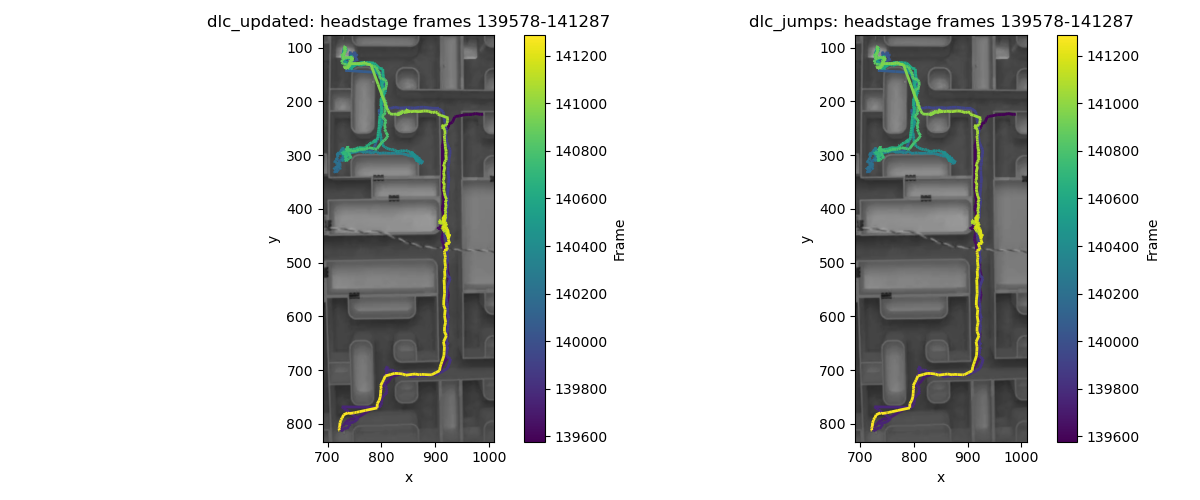

In [309]:
from matplotlib.collections import LineCollection
import matplotlib.cm as cm

# Define the frame indices for coloring (acts as time)
start_frame = 139578
end_frame = 141287
bodypart = 'headstage'

frames = np.arange(start_frame, end_frame)
x_vals = dlc_updated[bodypart]['x'][start_frame:end_frame].values
y_vals = dlc_updated[bodypart]['y'][start_frame:end_frame].values
x_vals_jumps = dlc_jumps[bodypart]['x'][start_frame:end_frame].values
y_vals_jumps = dlc_jumps[bodypart]['y'][start_frame:end_frame].values

# Create segments for LineCollection
points = np.array([x_vals, y_vals]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
points_jumps = np.array([x_vals_jumps, y_vals_jumps]).T.reshape(-1, 1, 2)
segments_jumps = np.concatenate([points_jumps[:-1], points_jumps[1:]], axis=1)

pad = 20
x_min_frame = max(int(np.floor(min(x_vals.min(), x_vals_jumps.min()))) - pad, 0)
x_max_frame = min(int(np.ceil(max(x_vals.max(), x_vals_jumps.max()))) + pad, maze_image.shape[1])
y_min_frame = max(int(np.floor(min(y_vals.min(), y_vals_jumps.min()))) - pad, 0)
y_max_frame = min(int(np.ceil(max(y_vals.max(), y_vals_jumps.max()))) + pad, maze_image.shape[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot for dlc_updated
axes[0].imshow(
    cv2.cvtColor(maze_image[y_min_frame:y_max_frame, x_min_frame:x_max_frame], cv2.COLOR_BGR2RGB),
    extent=[x_min_frame, x_max_frame, y_min_frame, y_max_frame]
)
lc = LineCollection(segments, cmap='viridis')
lc.set_array(frames[:-1])
lc.set_linewidth(2)
line = axes[0].add_collection(lc)
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title(f'dlc_updated: {bodypart} frames {start_frame}-{end_frame}')
axes[0].invert_yaxis()  
plt.colorbar(line, ax=axes[0], label='Frame')

# Plot for dlc_jumps
axes[1].imshow(
    cv2.cvtColor(maze_image[y_min_frame:y_max_frame, x_min_frame:x_max_frame], cv2.COLOR_BGR2RGB),
    extent=[x_min_frame, x_max_frame, y_min_frame, y_max_frame]
)
lc_jumps = LineCollection(segments_jumps, cmap='viridis')
lc_jumps.set_array(frames[:-1])
lc_jumps.set_linewidth(2)
line_jumps = axes[1].add_collection(lc_jumps)
axes[1].set_xlabel('x')
axes[1].set_ylabel('y')
axes[1].set_title(f'dlc_jumps: {bodypart} frames {start_frame}-{end_frame}')
axes[1].invert_yaxis()
plt.colorbar(line_jumps, ax=axes[1], label='Frame')

plt.tight_layout()
plt.show()


In [313]:
# Define a minimal movement threshold (in pixels)
minimal_movement_threshold = 300  # adjust as needed

# Calculate trial start and end indices
trial_durations = trial_times_maze.flatten()
trial_starts = np.concatenate([[0], np.cumsum(trial_durations)[:-1]])
trial_ends = np.cumsum(trial_durations)
fps = 40

minimal_movement_trials = 0
for start, end in zip(trial_starts, trial_ends):
    start_idx = int(np.round(start * fps))
    end_idx = int(np.round(end * fps))
    x_trial = x[start_idx:end_idx]
    y_trial = y[start_idx:end_idx]
    if len(x_trial) < 2:
        continue
    dx = np.diff(x_trial)
    dy = np.diff(y_trial)
    distances = np.sqrt(dx**2 + dy**2)
    total_movement = np.sum(distances)
    if total_movement < minimal_movement_threshold:
        minimal_movement_trials += 1

print(f"Number of trials with minimal movement (<{minimal_movement_threshold} pixels): {minimal_movement_trials}")

Number of trials with minimal movement (<300 pixels): 122


In [ ]:
import os
import matplotlib.image as mpimg

def plot_trials(dlc_raw_h5, dlc_updated, trial_times_maze, save_dir, maze_img):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    fps = 40

    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        # Get x/y limits for the current trial (for cropping the image)
        x_vals = dlc_updated['headstage']['x'][start_idx:end_idx]
        y_vals = dlc_updated['headstage']['y'][start_idx:end_idx]
        if len(x_vals) == 0 or len(y_vals) == 0:
            continue
        x_min, x_max = x_vals.min(), x_vals.max()
        y_min, y_max = y_vals.min(), y_vals.max()

        # Add 20 pixels padding, but keep within image bounds
        x_min_pad = max(x_min - 20, 0)
        x_max_pad = min(x_max + 20, img_width)
        y_min_pad = max(y_min - 20, 0)
        y_max_pad = min(y_max + 20, img_height)

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Plot raw
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[0].plot(
            dlc_raw_h5['headstage']['x'][start_idx:end_idx],
            dlc_raw_h5['headstage']['y'][start_idx:end_idx],
            lw=0.5,
            color ='orange'
        )
        axes[0].set_title(
            f'Trial {i+1} (dlc_raw_h5)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[0].invert_yaxis()
        axes[0].set_xlim(x_min_pad, x_max_pad)
        axes[0].set_ylim(y_max_pad, y_min_pad)

        # Plot updated
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[1].plot(
            x_vals,
            y_vals,
            lw=0.5,
            color='orange'
        )
        axes[1].set_title(
            f'Trial {i+1} (dlc_updated)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[1].invert_yaxis()
        axes[1].set_xlim(x_min_pad, x_max_pad)
        axes[1].set_ylim(y_max_pad, y_min_pad)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}.png"))
        plt.close(fig)

# Example usage:
plot_trials(
    dlc_raw_h5, dlc_updated, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_border_fixes",
    maze_image
)

In [340]:
import os
import matplotlib.image as mpimg

def plot_trials_all_bodyparts(df1, df2, trial_times_maze, save_dir, maze_img, bodyparts):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    fps = 40

    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    # Assign a color to each bodypart
    import matplotlib.pyplot as plt
    from matplotlib import cm
    color_map = cm.get_cmap('tab10', len(bodyparts))
    bodypart_colors = {bp: color_map(i) for i, bp in enumerate(bodyparts)}

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Plot raw
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        for bp in bodyparts:
            axes[0].plot(
                df1[(bp, 'x')][start_idx:end_idx],
                df1[(bp, 'y')][start_idx:end_idx],
                lw=0.7,
                color=bodypart_colors[bp],
                label=bp
            )
        axes[0].set_title(
            f'Trial {i+1} (dlc_updated)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)

        # Plot updated
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        for bp in bodyparts:
            axes[1].plot(
                df2[(bp, 'x')][start_idx:end_idx],
                df2[(bp, 'y')][start_idx:end_idx],
                lw=0.7,
                color=bodypart_colors[bp],
                label=bp
            )
        axes[1].set_title(
            f'Trial {i+1} (dlc_jumps)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)

        # Only add legend to the first plot
        axes[0].legend(loc='upper right', fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_all_bodyparts.png"))
        plt.close(fig)

# Example usage:
plot_trials_all_bodyparts(
    dlc_updated, dlc_jumps, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_all_bodyparts",
    maze_image,
    bodyparts
)

C:\Users\Almog\AppData\Local\Temp\ipykernel_17460\632495546.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = cm.get_cmap('tab10', len(bodyparts))


MemoryError: Unable to allocate 4.82 MiB for an array with shape (1018, 1240, 4) and data type uint8

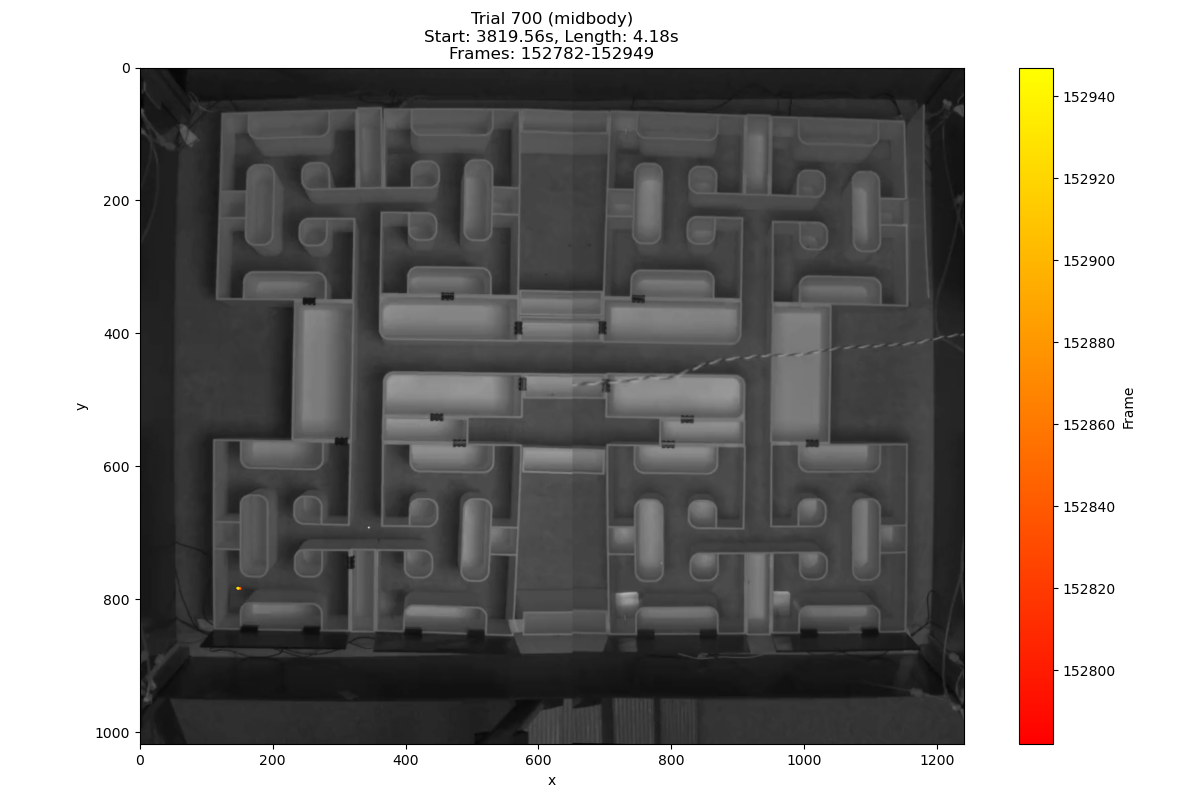

In [349]:
import os
from matplotlib.collections import LineCollection
import matplotlib.pyplot as plt
import numpy as np

def plot_bodypart_trajectory_colormap(
    dlc_updated, trial_times_maze, save_dir, maze_img, bodypart='headstage', fps=40, cmap='autumn'
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_vals = dlc_updated[bodypart]['x'][start_idx:end_idx].values
        y_vals = dlc_updated[bodypart]['y'][start_idx:end_idx].values
        # likelihood = dlc_updated[bodypart]['likelihood'][start_idx:end_idx].values
        # valid = likelihood > 0

        # if np.sum(valid) < 2:
        #     continue

        # Prepare segments for LineCollection
        points = np.array([x_vals, y_vals]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]], axis=1)
        frames = np.arange(start_idx, end_idx)

        fig, ax = plt.subplots(figsize=(12, 8))
        ax.imshow(maze_img, extent=[0, img_width, img_height, 0])
        lc = LineCollection(segments, cmap=cmap)
        lc.set_array(frames[:-1])
        lc.set_linewidth(2)
        line = ax.add_collection(lc)
        ax.set_title(
            f'Trial {i+1} ({bodypart})\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.invert_yaxis()
        ax.set_xlim(0, img_width)
        ax.set_ylim(img_height, 0)
        plt.colorbar(line, ax=ax, label='Frame')
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_{bodypart}_colormap.png"))
        plt.close(fig)

# Example usage:

bodypart='midbody'

plot_bodypart_trajectory_colormap(
    dlc_updated, trial_times_maze,
    rf"C:\Users\Almog\Desktop\trial_trajectories_{bodypart}_colormap",
    maze_image,
    bodypart=bodypart
)

In [339]:
trial_times_maze = trial_times_maze - 2
trial_times_maze

array([[11.8051    ],
       [ 4.14196667],
       [ 4.2557    ],
       [ 4.30603333],
       [ 6.13766667],
       [ 2.658     ],
       [ 4.56676667],
       [10.67326667],
       [ 4.23813333],
       [ 4.72843333],
       [ 5.00213333],
       [ 6.97836667],
       [10.88176667],
       [ 2.41616667],
       [ 6.25536667],
       [ 4.23683333],
       [ 4.2932    ],
       [ 4.51456667],
       [ 4.24313333],
       [ 9.53536667],
       [ 4.20433333],
       [16.5619    ],
       [ 6.01693333],
       [14.72616667],
       [ 4.46593333],
       [ 3.68743333],
       [ 4.34553333],
       [ 4.31746667],
       [ 5.31726667],
       [ 3.58546667],
       [ 2.23306667],
       [ 6.66956667],
       [ 7.10143333],
       [ 4.22896667],
       [ 4.22076667],
       [ 4.26836667],
       [ 4.6369    ],
       [ 3.37093333],
       [ 2.72493333],
       [ 4.23133333],
       [ 4.47563333],
       [ 4.37173333],
       [ 4.20973333],
       [ 2.18953333],
       [ 2.83683333],
       [ 4

KeyboardInterrupt: 

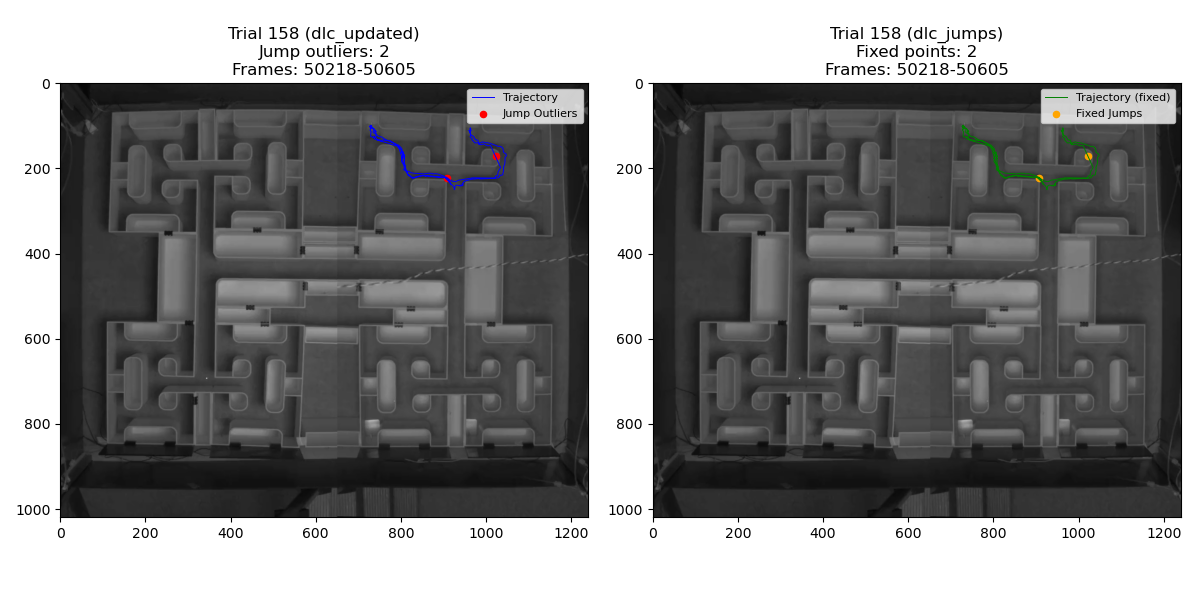

In [314]:
import os
import matplotlib.image as mpimg

def plot_trials_jumps_highlighted(
    dlc_updated, dlc_jumps, trial_times_maze, save_dir, maze_img, bodypart='headstage', jump_percentile=99.5, fps=40
):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        x_upd = dlc_updated[bodypart]['x'][start_idx:end_idx].values
        y_upd = dlc_updated[bodypart]['y'][start_idx:end_idx].values
        x_jmp = dlc_jumps[bodypart]['x'][start_idx:end_idx].values
        y_jmp = dlc_jumps[bodypart]['y'][start_idx:end_idx].values

        # Only consider frames with likelihood > 0
        likelihood = dlc_updated[bodypart]['likelihood'][start_idx:end_idx].values
        valid = likelihood > 0

        # Calculate jumps in dlc_updated
        dx = np.diff(x_upd)
        dy = np.diff(y_upd)
        distances = np.sqrt(dx**2 + dy**2)
        valid_mask = valid[:-1] & valid[1:]
        if np.sum(valid_mask) == 0:
            continue
        jump_threshold = np.percentile(distances[valid_mask], jump_percentile)
        jump_points = np.where((distances > jump_threshold) & valid_mask)[0] + 1  # +1 to align with the second point

        # For dlc_jumps, highlight the fixed points (where the jump was in dlc_updated)
        fixed_points = jump_points

        fig, axes = plt.subplots(1, 2, figsize=(12, 6))

        # Plot dlc_updated with jump outliers marked
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[0].plot(x_upd[valid], y_upd[valid], lw=0.7, color='blue', label='Trajectory')
        if len(jump_points) > 0:
            axes[0].scatter(x_upd[jump_points], y_upd[jump_points], color='red', s=20, label='Jump Outliers')
        axes[0].set_title(
            f'Trial {i+1} (dlc_updated)\nJump outliers: {len(jump_points)}\nFrames: {start_idx}-{end_idx}'
        )
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)
        axes[0].legend(loc='upper right', fontsize=8)

        # Plot dlc_jumps with fixed points highlighted
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        axes[1].plot(x_jmp[valid], y_jmp[valid], lw=0.7, color='green', label='Trajectory (fixed)')
        if len(fixed_points) > 0:
            axes[1].scatter(x_jmp[fixed_points], y_jmp[fixed_points], color='orange', s=20, label='Fixed Jumps')
        axes[1].set_title(
            f'Trial {i+1} (dlc_jumps)\nFixed points: {len(fixed_points)}\nFrames: {start_idx}-{end_idx}'
        )
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)
        axes[1].legend(loc='upper right', fontsize=8)

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_jumps_highlighted.png"))
        plt.close(fig)

# Example usage:
plot_trials_jumps_highlighted(
    dlc_updated, dlc_jumps, trial_times_maze,
    r"C:\Users\Almog\Desktop\trial_trajectories_jumps_highlighted",
    maze_image,
    bodypart='headstage',
    jump_percentile=99.5
)

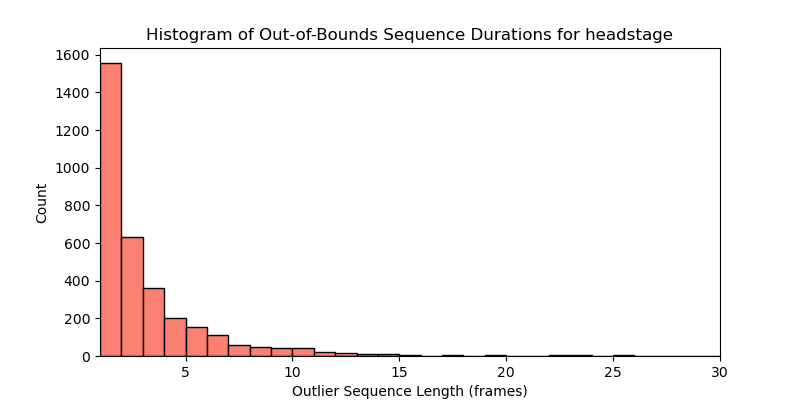

In [89]:
# Plot histogram of outlier durations (sequence lengths) for a given bodypart
bodypart = 'headstage'  # Change as needed

out_of_bounds = dlc_updated[(bodypart, 'out_of_bounds')].values

# Find lengths of consecutive True sequences
durations = []
current_length = 0
for val in out_of_bounds:
    if val:
        current_length += 1
    else:
        if current_length > 0:
            durations.append(current_length)
            current_length = 0
# If the last sequence ends at the last frame
if current_length > 0:
    durations.append(current_length)

plt.figure(figsize=(8, 4))
plt.hist(durations, bins=range(1, max(durations)+2), color='salmon', edgecolor='k')
plt.xlabel('Outlier Sequence Length (frames)')
plt.ylabel('Count')
plt.xlim(1, 30)
plt.title(f'Histogram of Out-of-Bounds Sequence Durations for {bodypart}')
plt.show()

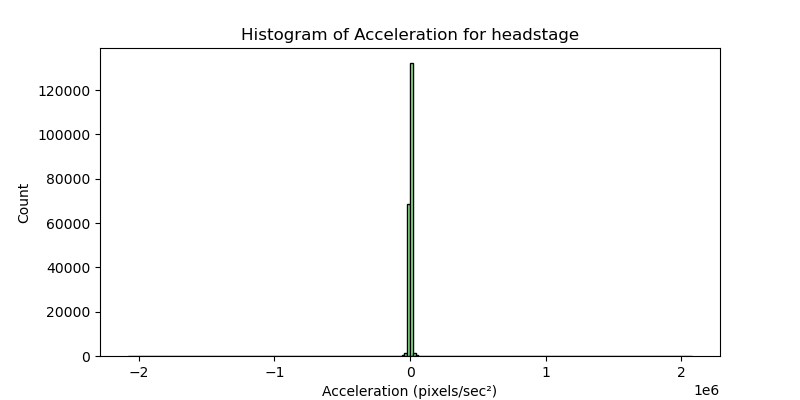

In [ ]:
bodypart = 'headstage'  # Change as needed
fps = 40

x = dlc_updated[bodypart]['x'].values
y = dlc_updated[bodypart]['y'].values

# Calculate speed (pixels/sec) between consecutive frames
dx = np.diff(x)
dy = np.diff(y)
distances = np.sqrt(dx**2 + dy**2)
speed = distances * fps  # pixels/sec

# Calculate acceleration (change in speed per second)
acceleration = np.diff(speed) * fps  # pixels/sec^2

def print_stats(arr, print_stats(arr, name): name):
    print(f"{name} statistics:") statistics:")
    print(f"  Median:  Median: {np.median(arr):.2f}") {np.median(arr):.2f}")
    print(f"  Mean:  Mean: {np.mean(arr):.2f}") {np.mean(arr):.2f}")
    print(f"  Min:  Min: {np.min(arr):.2f}") {np.min(arr):.2f}")
    print(f"  Max:  Max: {np.max(arr):.2f}") {np.max(arr):.2f}")
    print(f"  25th  25th percentile: percentile: {np.percentile(arr, {np.percentile(arr, 25):.2f}") 25):.2f}")
    print(f"  75th  75th percentile: percentile: {np.percentile(arr, {np.percentile(arr, 75):.2f}") 75):.2f}")
    print()

print_stats(speed, "Speed") "Speed")
print_stats(acceleration, "Acceleration") "Acceleration")

plt.figure(figsize==(14,(14, 4)) 4))
plt.subplot(1, 2, 2,
plt.hist(speed, bins bins==200,200, color color=='skyblue
plt.xlabel('Speed (pixels/sec)')
plt.ylabel('Count')
plt.title(f'Histogram of of Speed Speed for for

plt.subplot(1, 2, 2,
plt.hist(acceleration, bins bins==200,200, color color=='lightgreen
plt.xlabel('Acceleration (pixels/sec²)')
plt.ylabel('Count')
plt.title(f'Histogram of of Acceleration Acceleration 

plt.tight_layout()
plt.show()for for {bodypart}') {bodypart}') (pixels/sec²)')','lightgreen', edgecolor edgecolor=='k')'k') 2) 2) {bodypart}') {bodypart}') (pixels/sec)')','skyblue', edgecolor edgecolor=='k')'k') 1) 1)

Speed statistics:
  Median: 53.54
  Mean: 137.99
  Min: 0.00
  Max: 51930.39
  25th percentile: 18.32
  75th percentile: 177.91
  90th percentile: 333.82
  99th percentile: 748.03

Acceleration statistics:
  Median: 0.00
  Mean: 0.03
  Min: -2077120.00
  Max: 2076046.50
  25th percentile: -1177.78
  75th percentile: 1170.17
  90th percentile: 3888.76
  99th percentile: 21457.69



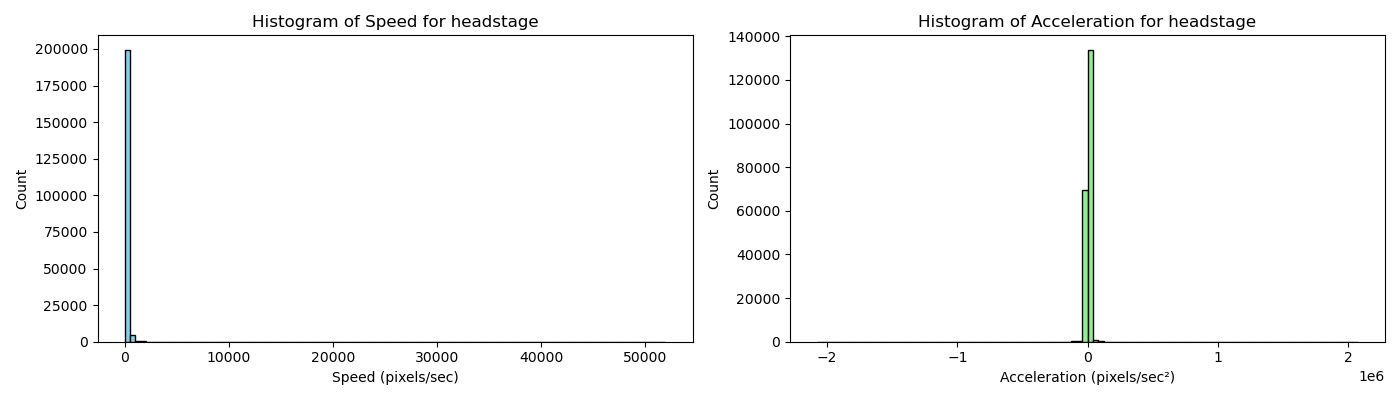

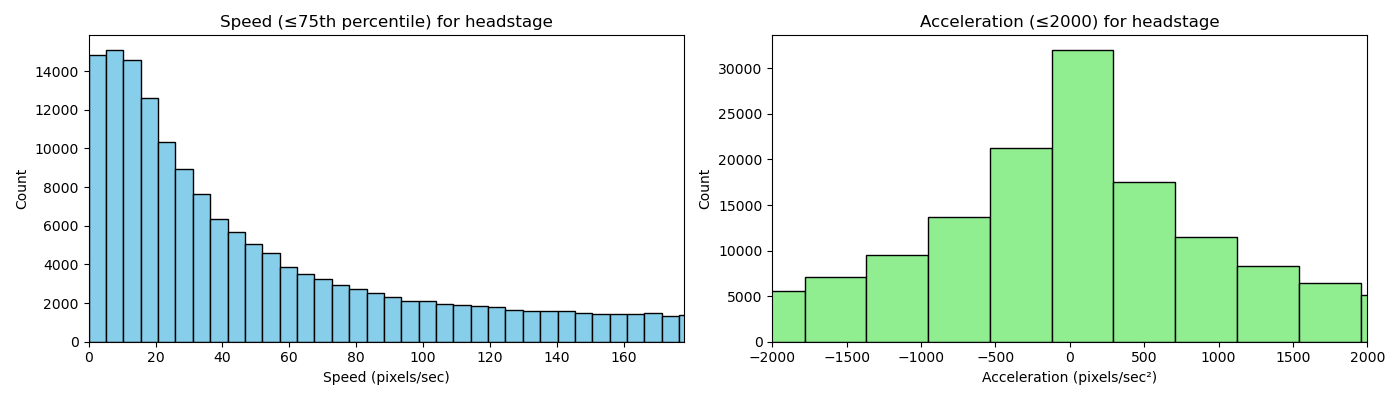

In [102]:
bodypart = 'headstage'  # Change as needed
fps = 40

x = dlc_updated[bodypart]['x'].values
y = dlc_updated[bodypart]['y'].values

# Calculate speed (pixels/sec) between consecutive frames
dx = np.diff(x)
dy = np.diff(y)
distances = np.sqrt(dx**2 + dy**2)
speed = distances * fps  # pixels/sec

# Calculate acceleration (change in speed per second)
acceleration = np.diff(speed) * fps  # pixels/sec^2

def print_stats(arr, name):
    print(f"{name} statistics:")
    print(f"  Median: {np.median(arr):.2f}")
    print(f"  Mean: {np.mean(arr):.2f}")
    print(f"  Min: {np.min(arr):.2f}")
    print(f"  Max: {np.max(arr):.2f}")
    print(f"  25th percentile: {np.percentile(arr, 25):.2f}")
    print(f"  75th percentile: {np.percentile(arr, 75):.2f}")
    print(f"  90th percentile: {np.percentile(arr, 90):.2f}")
    print(f"  99th percentile: {np.percentile(arr, 99):.2f}")
    print()

print_stats(speed, "Speed")
print_stats(acceleration, "Acceleration")

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.hist(speed, bins=100, color='skyblue', edgecolor='k')
plt.xlabel('Speed (pixels/sec)')
plt.ylabel('Count')
plt.title(f'Histogram of Speed for {bodypart}')

plt.subplot(1, 2, 2)
plt.hist(acceleration, bins=100, color='lightgreen', edgecolor='k')
plt.xlabel('Acceleration (pixels/sec²)')
plt.ylabel('Count')
plt.title(f'Histogram of Acceleration for {bodypart}')

plt.tight_layout()
plt.show()

# Plot histograms with axis limited to 75th percentile
speed_75 = np.percentile(speed, 75)
accel_75 = np.percentile(acceleration, 75)

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.hist(speed, bins=10000, color='skyblue', edgecolor='k')
plt.xlabel('Speed (pixels/sec)')
plt.ylabel('Count')
plt.title(f'Speed (≤75th percentile) for {bodypart}')
plt.xlim(0, speed_75)

plt.subplot(1, 2, 2)
plt.hist(acceleration, bins=10000, color='lightgreen', edgecolor='k')
plt.xlabel('Acceleration (pixels/sec²)')
plt.ylabel('Count')
plt.title(f'Acceleration (≤2000) for {bodypart}')
plt.xlim(-2000, 2000)

plt.tight_layout()
plt.show()

Total number of jumps for headstage (>99.9th percentile): 206


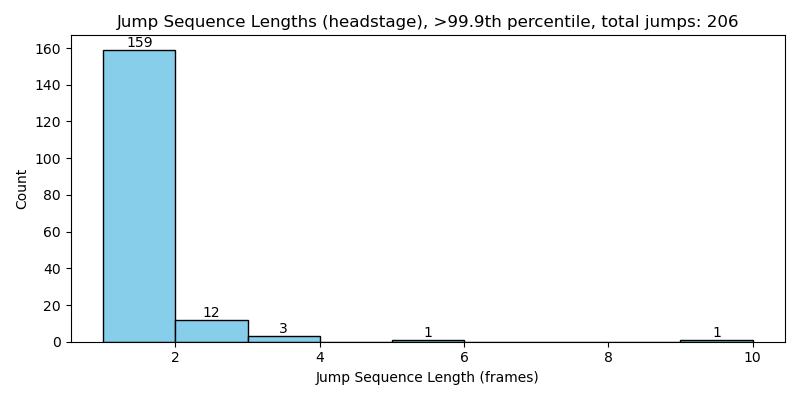

In [113]:
bodypart = 'headstage'  # Change as needed
fps = 40
percentile = 99.9  # You can adjust this value

x = dlc_updated[bodypart]['x'].values
y = dlc_updated[bodypart]['y'].values
likelihood = dlc_updated[bodypart]['likelihood'].values
valid = (likelihood[:-1] > 0) & (likelihood[1:] > 0)

dx = np.diff(x)
dy = np.diff(y)
distances = np.sqrt(dx**2 + dy**2)
valid_distances = distances[valid]

jump_threshold = np.percentile(valid_distances, percentile)
jump_mask = (distances > jump_threshold) & valid

# Find lengths of consecutive jump sequences
jump_lengths = []
current_length = 0
for is_jump in jump_mask:
    if is_jump:
        current_length += 1
    else:
        if current_length > 0:
            jump_lengths.append(current_length)
            current_length = 0
if current_length > 0:
    jump_lengths.append(current_length)

total_jumps = np.sum(jump_mask)
print(f"Total number of jumps for {bodypart} (>{percentile}th percentile): {total_jumps}")

plt.figure(figsize=(8, 4))
if jump_lengths:
    bins = range(1, max(jump_lengths)+2)
    counts, _, patches = plt.hist(jump_lengths, bins=bins, color='skyblue', edgecolor='k')
    plt.xlabel('Jump Sequence Length (frames)')
    plt.ylabel('Count')
    plt.title(f'Jump Sequence Lengths ({bodypart}), >{percentile}th percentile, total jumps: {total_jumps}')
    # Annotate each bar with its count
    for count, patch in zip(counts, patches):
        if count > 0:
            plt.text(patch.get_x() + patch.get_width()/2, count, int(count),
                     ha='center', va='bottom', fontsize=10)
else:
    plt.text(0.5, 0.5, 'No jump sequences found', ha='center', va='center')
plt.tight_layout()
plt.show()


In [88]:
# Count the number of sequences of each length in durations
duration_counts = {length: durations.count(length) for length in set(durations)}
print(f"Count of out-of-bounds sequence lengths: {duration_counts}")

Count of out-of-bounds sequence lengths: {1: 1558, 2: 634, 3: 359, 4: 200, 5: 152, 6: 113, 7: 59, 8: 46, 9: 41, 10: 45, 11: 21, 12: 16, 13: 10, 14: 9, 15: 7, 16: 2, 17: 3, 18: 2, 19: 3, 21: 1, 22: 5, 23: 4, 25: 3, 27: 2, 28: 1, 29: 1, 31: 2, 33: 1, 39: 1, 40: 1, 43: 1, 49: 1, 50: 1, 56: 1, 85: 1, 104: 1, 109: 1}


In [ ]:
import os
import matplotlib.image as mpimg

def plot_trials_all_bodyparts(df1, df2, trial_times_maze, updated_mask, save_dir, maze_img, bodyparts):
    os.makedirs(save_dir, exist_ok=True)
    trial_durations = trial_times_maze.flatten()
    trial_starts = [0] + list(np.cumsum(trial_durations)[:-1])
    trial_ends = np.cumsum(trial_durations)
    fps = 40

    img_height, img_width = maze_img.shape[0], maze_img.shape[1]

    # Assign a color to each bodypart
    import matplotlib.pyplot as plt
    from matplotlib import cm
    color_map = cm.get_cmap('tab10', len(bodyparts))
    bodypart_colors = {bp: color_map(i) for i, bp in enumerate(bodyparts)}

    for i, (start, end) in enumerate(zip(trial_starts, trial_ends)):
        start_idx = int(np.round(start * fps))
        end_idx = int(np.round(end * fps))

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        # Plot raw
        axes[0].imshow(maze_img, extent=[0, img_width, img_height, 0])
        for bp in bodyparts:
            mask = df1[(bp, 'likelihood')][start_idx:end_idx] > 0
            axes[0].plot(
                df1[(bp, 'x')][start_idx:end_idx][mask],
                df1[(bp, 'y')][start_idx:end_idx][mask],
                lw=0.7,
                color=bodypart_colors[bp],
                label=bp
            )
        axes[0].set_title(
            f'Trial {i+1} (dlc_updated)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[0].invert_yaxis()
        axes[0].set_xlim(0, img_width)
        axes[0].set_ylim(img_height, 0)

        # Plot updated
        axes[1].imshow(maze_img, extent=[0, img_width, img_height, 0])
        for bp in bodyparts:
            mask = updated_mask[start_idx:end_idx] if bp == 'headstage' else (df2[(bp, 'likelihood')][start_idx:end_idx] > 0)
            axes[1].plot(
                df2[(bp, 'x')][start_idx:end_idx][mask],
                df2[(bp, 'y')][start_idx:end_idx][mask],
                lw=0.7,
                color=bodypart_colors[bp],
                label=bp
            )
        axes[1].set_title(
            f'Trial {i+1} (dlc_jumps)\nStart: {start:.2f}s, Length: {trial_durations[i]:.2f}s\nFrames: {start_idx}-{end_idx}'
        )
        axes[1].invert_yaxis()
        axes[1].set_xlim(0, img_width)
        axes[1].set_ylim(img_height, 0)

        # Only add legend to the first plot
        axes[0].legend(loc='upper right', fontsize=8)
        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f"trial_{i+1:03d}_all_bodyparts.png"))
        plt.close(fig)

# Example usage:
plot_trials_all_bodyparts(
    dlc_updated, dlc_jumps, trial_times_maze, updated_mask,
    r"C:\Users\Almog\Desktop\trial_trajectories_all_bodyparts",
    maze_image,
    bodyparts
)

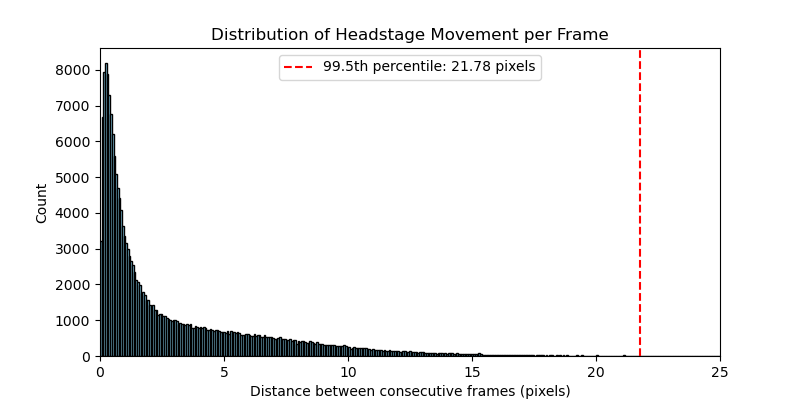

In [ ]:
# Calculate distances between consecutive frames for headstage bodypart
x = dlc_updated['headstage']['x'].values
y = dlc_updated['headstage']['y'].values

# Only consider frames where both consecutive likelihoods are > 0
likelihood = dlc_updated['headstage']['likelihood'].values
valid = (likelihood[:-1] > 0) & (likelihood[1:] > 0)

dx = np.diff(x)
dy = np.diff(y)
distances = np.sqrt(dx**2 + dy**2)

# Filter distances to only valid frames
valid_distances = distances[valid]

# percentile_95 = np.percentile(valid_distances, 95)
percentile_995 = np.percentile(valid_distances, 99.5)


plt.figure(figsize=(8, 4))
plt.hist(valid_distances, bins=2000, color='skyblue', edgecolor='k')
plt.axvline(percentile_995, color='red', linestyle='--', label=f'99.5th percentile: {percentile_995:.2f} pixels')
plt.xlabel('Distance between consecutive frames (pixels)')
plt.ylabel('Count')
plt.title('Distribution of Headstage Movement per Frame')
plt.xlim(0, 25)
plt.legend()
plt.show()

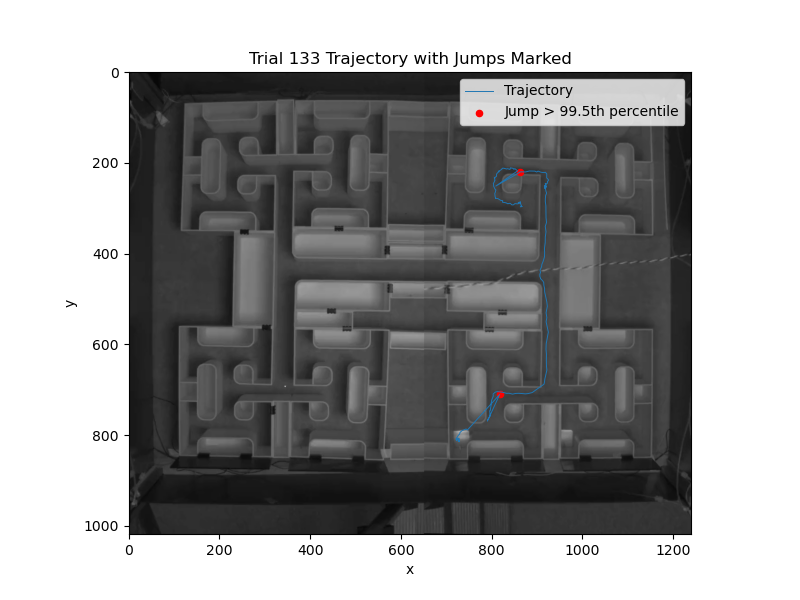

In [69]:
# Define the trial index you want to analyze (e.g., trial 133)
trial_idx = 132  # Python is 0-based, so trial 133 is index 132
fps = 40

# Calculate trial start and end indices
trial_durations = trial_times_maze.flatten()
trial_starts = np.concatenate([[0], np.cumsum(trial_durations)[:-1]])
trial_ends = np.cumsum(trial_durations)

start_idx = int(np.round(trial_starts[trial_idx] * fps))
end_idx = int(np.round(trial_ends[trial_idx] * fps))

# Extract x and y for the trial
x_trial = x[start_idx:end_idx]
y_trial = y[start_idx:end_idx]

# If you have a likelihood array for the trial, use it here. Otherwise, use all points as valid.
mask_trial = np.ones_like(x_trial, dtype=bool)

# Calculate movement between consecutive frames for the trial
dx_trial = np.diff(x_trial)
dy_trial = np.diff(y_trial)
distances_trial = np.sqrt(dx_trial**2 + dy_trial**2)

# Find the 99.5th percentile threshold for jumps
jump_threshold = np.percentile(distances_trial[mask_trial[1:]], 99.5)

# Find indices where the movement exceeds the threshold
jump_points = np.where((distances_trial > jump_threshold) & mask_trial[1:] & mask_trial[:-1])[0] + 1  # +1 to align with the second point in the diff

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(maze_image, cv2.COLOR_BGR2RGB), extent=[0, maze_image.shape[1], maze_image.shape[0], 0])
plt.plot(x_trial[mask_trial], y_trial[mask_trial], lw=0.7, label='Trajectory')
plt.scatter(x_trial[jump_points], y_trial[jump_points], color='red', s=20, label='Jump > 99.5th percentile')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Trial 133 Trajectory with Jumps Marked')
plt.gca().invert_yaxis()
plt.legend()
plt.xlim(0, maze_image.shape[1])
plt.ylim(maze_image.shape[0], 0)
plt.gca().set_aspect('equal')
plt.show()


In [71]:
# Print the distance of each jump point from the previous point in the trial
for idx in jump_points:
    dist = distances_trial[idx - 1]  # idx-1 because np.diff aligns with the second point
    print(f"Jump at index {idx}: distance from previous point = {dist:.2f} pixels")

Jump at index 72: distance from previous point = 61.13 pixels
Jump at index 192: distance from previous point = 64.62 pixels


In [75]:
distances_trial[185:195]

array([ 0.85296375,  3.3483293 ,  3.0651526 ,  4.6614532 ,  9.980886  ,
        2.6209042 , 64.62485   , 52.852356  , 26.426178  , 13.213089  ],
      dtype=float32)

In [140]:
dlc_updated[990:1020]

headstage                               ear_L                         \
                x           y likelihood            x           y likelihood   
990    996.361755  146.561584   0.736268   978.945190  141.147812   0.755490   
991    999.041931  146.493454   0.672059   983.010132  141.340073   0.659773   
992   1222.287109   59.582638   0.000000   985.538879  143.839615   0.441832   
993   1222.594482   59.571701   0.000000   989.392029  144.477676   0.380195   
994   1222.781250   59.814327   0.000000   991.690796  142.847076   0.506755   
995   1222.816772   59.885307   0.000000   994.826538  144.565887   0.486423   
996   1222.892090   59.844807   0.000000   999.164246  144.432297   0.583043   
997   1223.088867   59.692078   0.000000  1218.864624   64.209885   0.000000   
998   1222.882324   59.649879   0.000000  1011.338196  145.756516   0.500493   
999   1222.985352   59.730381   0.000000  1218.509888   64.207199   0.000000   
1000  1222.991455   59.829376   0.000000  1218.344360   63.578281   0.000000   
1001  1222.841309   59.721161   0.000000  1218.408081   64.077461   0.000000   
1002  1222.919067   59.925682   0.000000  1218.514282   64.361710   0.000000   
1003  1222.956421   59.897152   0.000000  1003.115112  149.989532   0.576225   
1004  1222.698853   60.008354   0.000000  1001.451294  154.231110   0.406941   
1005  1222.704834   59.745014   0.000000  1001.644043  152.476135   0.480647   
1006  1031.675781  199.234146   0.700934  1044.025757  184.673767   0.655867   
1007  1026.187500  210.094925   0.656998  1042.212646  193.292282   0.608336   
1008  1023.985168  213.418777   0.829299  1041.302856  200.058990   0.746489   
1009  1021.936890  214.409790   0.758817  1039.328979  206.196548   0.835517   
1010  1017.515503  220.025650   0.621739  1034.665405  213.728867   0.818674   
1011  1009.187195  222.720093   0.819520  1030.978149  219.947144   0.865036   
1012  1006.680786  222.633728   0.730975  1022.660278  223.720947   0.709319   
1013   997.532410  221.500824   0.630864  1013.077393  226.067078   0.523152   
1014   992.795471  221.272308   0.756607  1007.567627  226.397659   0.521397   
1015   981.270630  221.143158   0.842804   998.570251  226.253128   0.625810   
1016   973.405396  221.441193   0.748723   992.580627  225.119446   0.582684   
1017   965.622803  222.019089   0.860572   983.742249  228.019012   0.581710   
1018   945.930420  229.454010   0.852793   973.108765  221.167603   0.427885   
1019   936.084229  233.171478   0.848904  1219.393433   63.897366   0.000000   

            ear_R                             midbody                         \
                x           y likelihood            x           y likelihood   
990    981.830627  156.286652   0.698070   963.472961  155.007950   0.885624   
991    985.077332  155.881180   0.608830   964.905823  153.469788   0.860201   
992    985.468079  154.484879   0.440401   966.613647  152.847031   0.831362   
993   1233.278076   70.871040   0.000000   966.039246  153.122803   0.817736   
994    990.574585  153.759903   0.485119   966.001648  152.804367   0.752058   
995    996.556702  154.487793   0.406513   972.289246  153.302429   0.804279   
996    999.437866  155.457825   0.414685   980.325317  150.788406   0.956426   
997   1233.802734   70.818016   0.000000   987.499634  147.648865   0.840151   
998   1009.312866  157.281693   0.385990   992.414185  147.102951   0.911986   
999   1233.413818   70.714798   0.000000   999.975769  146.302383   0.815004   
1000  1233.165527   70.611427   0.000000  1005.565308  146.576416   0.850548   
1001  1233.143066   70.732719   0.000000  1010.212891  146.288895   1.000000   
1002  1233.210571   70.901169   0.000000  1017.903015  147.804703   1.000000   
1003  1010.463867  135.428482   0.536393  1019.715515  148.491272   0.852435   
1004  1007.593628  137.530746   0.399969  1023.002625  151.364105   0.898776   
1005  1009.193970  137.818161   0.484466  1023.633240  154.307663   0.916419   
1006  1

In [153]:
dlc_updated[dlc_updated['headstage']['likelihood'] == 0]

headstage                              ear_L                         \
                  x          y likelihood            x           y likelihood   
0       1225.746216  58.650742        0.0  1172.654541  938.546143   0.000000   
1       1223.666138  59.027889        0.0  1227.202393  895.803162   0.000000   
2       1223.600830  58.788288        0.0  1227.873291  895.815369   0.000000   
3       1223.532227  58.805294        0.0  1227.693848  895.700745   0.000000   
4       1223.592529  58.846447        0.0  1227.953125  895.617310   0.000000   
...             ...        ...        ...          ...         ...        ...   
203900  1223.717896  59.835934        0.0   975.892395  147.702057   0.498149   
203901  1223.756958  59.882473        0.0   972.796631  173.154663   0.505148   
204200  1222.627319  59.469452        0.0   968.074280  300.384735   0.380554   
205063  1222.979492  59.234760        0.0   959.064697  764.126526   0.440851   
205064  1223.173950  59.287937        0.0   963.186584  764.631897   0.344889   

              ear_R                            midbody                         \
                  x           y likelihood           x           y likelihood   
0       1229.988281   69.945328   0.000000  269.806732  860.644958   0.000000   
1       1229.722046   70.649147   0.000000  278.490997  859.902344   0.000000   
2       1229.945190   70.707748   0.000000  278.249176  859.757812   0.000000   
3       1230.006592   70.668343   0.000000  278.343353  859.932312   0.000000   
4       1229.897339   70.772102   0.000000  278.521606  860.028931   0.000000   
...             ...         ...        ...         ...         ...        ...   
203900   978.560608  160.114319   0.481285  961.988159  160.277634   0.875707   
203901   956.698181  174.880890   0.563310  964.456787  158.794357   0.999876   
204200  1232.323242   71.789917   0.000000  964.401367  306.338318   0.332724   
205063  1231.634521   70.368965   0.000000  970.805664  774.394348   0.927102   
205064  1231.580688   70.188652   0.000000  972.292969  777.235413   0.920964   

          tailbase                        weighted                 
                 x           y likelihood        x   y likelihood  
0       302.025085  100.989944   0.441331      NaN NaN        NaN  
1       101.449989  858.413940   0.000000      NaN NaN        NaN  
2       101.288437  858.461731   0.000000      NaN NaN        NaN  
3       101.383194  858.350952   0.000000      NaN NaN        NaN  
4       101.431572  858.378052   0.000000      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
203900  962.055847  181.975708   0.451563      NaN NaN        NaN  
203901  974.553406  143.254074   0.542869      NaN NaN        NaN  
204200  306.676636  858.725037   0.000000      NaN NaN        NaN  
205063  990.876587  777.534973   0.431232      NaN NaN        NaN  
205064  971.495056  759.343445   0.508203      NaN NaN        NaN  

[1493 rows x 18 columns]

In [ ]:
def calculate_weighted_coordinates(row):
    nose_likelihood = row['nose']['likelihood']
    head_stage_likelihood = row['head_stage']['likelihood']
    
    # If either nose or head_stage has a likelihood at least 0.6, pick the one with the higher likelihood.
    if nose_likelihood >= 0.6 or head_stage_likelihood >= 0.6:
        if nose_likelihood >= head_stage_likelihood:
            return (row['nose']['x'], row['nose']['y'], nose_likelihood)
        else:
            return (row['head_stage']['x'], row['head_stage']['y'], head_stage_likelihood)
    
    # Both nose and head_stage have low likelihood, so use weighted sum of all other body parts.
    body_parts = ['ear_R', 'ear_L', 'mid_body', 'tail_base']
    total_weight = 0
    weighted_x = 0
    weighted_y = 0
    likelihoods = []

    for part in body_parts:
        likelihood = row[part]['likelihood']
        likelihoods.append(likelihood)
        if likelihood > 0:
            weighted_x += row[part]['x'] * likelihood
            weighted_y += row[part]['y'] * likelihood
            total_weight += likelihood

    if total_weight > 0:
        weighted_x /= total_weight
        weighted_y /= total_weight
        weighted_likelihood = sum(likelihood * (likelihood / total_weight) for likelihood in likelihoods)
    else:
        weighted_likelihood = 0

    return (weighted_x, weighted_y, weighted_likelihood)

for i, row in enumerate(dlc_raw_h5.iterrows()):
    dlc_raw_h5.loc[i, ('weighted', ['x', 'y', 'likelihood'])] = calculate_weighted_coordinates(row[1])

# Display the updated dataframe
dlc_raw_h5

nose                               ear_L                         \
                x           y likelihood            x           y likelihood   
0      930.863403  250.882019   0.201783  1138.078735  423.674072   0.377326   
1      995.247681  229.974350   0.101296  1137.368652  424.024597   0.368687   
2      926.486694  261.117310   0.209730  1137.525269  423.668335   0.360559   
3      925.783569  260.580078   0.201815   938.498352  256.050842   0.414909   
4      925.632507  258.589050   0.181430   937.801636  255.904114   0.433897   
...           ...         ...        ...          ...         ...        ...   
52670  146.793533  132.550720   0.325325   150.772186  146.755646   0.417223   
52671  146.342316  132.174072   0.298409   149.939285  146.140671   0.450341   
52672  146.192795  131.492966   0.288205   149.705826  145.472641   0.473696   
52673  146.396698  131.411316   0.280032   149.407074  145.541229   0.456315   
52674  146.382507  131.423920   0.279323   149.399643  145.540253   0.455801   

            ear_R                           mid_body  ...             \
                x           y likelihood           x  ... likelihood   
0      935.880066  241.502914   0.378170  962.458496  ...   0.790137   
1      986.723694  236.377441   0.299528  953.868896  ...   0.787700   
2      930.504333  246.332520   0.452268  951.539062  ...   0.804729   
3      930.126343  245.383942   0.544846  951.739685  ...   0.790117   
4      928.336243  244.173874   0.507018  951.254395  ...   0.860785   
...           ...         ...        ...         ...  ...        ...   
52670  155.648575  137.741913   0.483237  167.702057  ...   0.995947   
52671  155.669800  137.067810   0.482478  166.821838  ...   0.985281   
52672  155.833298  136.576111   0.487797  166.816574  ...   0.977104   
52673  156.001068  136.763504   0.464179  166.374542  ...   0.973690   
52674  155.992279  136.761490   0.464027  166.373322  ...   0.973629   

         tail_base                          head_stage                         \
                 x           y likelihood            x           y likelihood   
0       931.504333  250.539566   0.554688  1234.689331  928.418213   0.000000   
1       926.760315  256.584137   0.685993  1234.713623  928.493652   0.000000   
2      1164.361328  436.043121   0.480829  1234.776733  928.549927   0.000000   
3       981.033569  231.014069   0.523580  1234.621460  928.349304   0.000000   
4       980.199829  230.937119   0.556051  1234.547607  928.377869   0.000000   
...            ...         ...        ...          ...         ...        ...   
52670   183.646530  152.012222   0.661626   151.734329  142.017899   0.372288   
52671   183.523849  152.230026   0.652700   150.617142  140.283203   0.345683   
52672   183.516800  152.270477   0.668461   149.806488  139.150513   0.322688   
52673   183.404236  152.316010   0.655666   150.240280  139.051407   0.313202   
52674   183.402084  152.314224   0.656043   150.234192  139.060226   0.313019   

          weighted                         
                 x           y likelihood  
0       981.048504  273.710844   0.579617  
1       981.367066  275.504449   0.614735  
2      1027.729483  316.801175   0.578223  
3       950.889791  241.274438   0.601476  
4       950.676782  240.674097   0.634281  
...            ...         ...        ...  
52670   166.787701  147.417750   0.718229  
52671   166.011931  147.564739   0.712769  
52672   165.934570  147.357884   0.714946  
52673   165.828683  147.628221   0.706573  
52674   165.831219  147.629365   0.706578  

[52675 rows x 21 columns]

In [299]:
# Restore the top level index (scorer) with the file name
h5_file = pd.concat({file_name: dlc_updated}, axis=1)
# Restore the index column names
h5_file.columns.names = ['scorer', 'bodyparts', 'coords']
h5_file

scorer    NPC1_2025_08_14_13_02_08_stitched_gammaDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle3_snapshot_150  \
bodyparts                                                                                             headstage   
coords                                                                                                        x   
0                                                1225.746216                                                      
1                                                1223.666138                                                      
2                                                1223.600830                                                      
3                                                1223.532227                                                      
4                                                1223.592529                                                      
...                                                      ...                                                      
205113                                            920.526733                                                      
205114                                            920.636597                                                      
205115                                            919.783875                                                      
205116                                            920.346497                                                      
205117                                            921.568604                                                      

scorer                                                                \
bodyparts                               ear_L                          
coords              y likelihood            x           y likelihood   
0           58.650742   0.000000  1172.654541  938.546143   0.000000   
1           59.027889   0.000000  1227.202393  895.803162   0.000000   
2           58.788288   0.000000  1227.873291  895.815369   0.000000   
3           58.805294   0.000000  1227.693848  895.700745   0.000000   
4           58.846447   0.000000  1227.953125  895.617310   0.000000   
...               ...        ...          ...         ...        ...   
205113     642.190735   0.857957   911.487671  657.983948   0.913761   
205114     634.909302   0.818240   912.046387  648.719788   0.878790   
205115     625.549255   0.927296   912.722107  643.703064   0.911139   
205116     617.812866   0.833715   911.399475  632.437439   0.866492   
205117     611.505493   0.823855   911.846497  627.164124   0.913876   

scorer                                                                 \
bodyparts        ear_R                            midbody               
coords               x           y likelihood           x           y   
0          1229.988281   69.945328   0.000000  269.806732  860.644958   
1          1229.722046   70.649147   0.000000  278.490997  859.902344   
2          1229.945190   70.707748   0.000000  278.249176  859.757812   
3          1230.006592   70.668343   0.000000  278.343353  859.932312   
4          1229.897339   70.772102   0.000000  278.521606  860.028931   
...                ...         ...        ...         ...         ...   
205113      931.593140  660.043640   0.933497  925.523438  684.174805   
205114      931.889465  653.111023   0.898839  925.250061  676.432678   
205115      931.763916  646.414734   0.832285  923.569580  670.815979   
205116      930.704834  634.988586   0.903648  923.122864  659.225769   
205117      931.593140  631.825439   0.848636  923.498840  654.304016   

scorer                                                                \
bodyparts               tailbase                        weighted       
coords    likelihood           x           y likelihood        x   y   
0           0.000000  302.025085  100.989944   0.441331      NaN NaN   
1           0.000000  101.449989  858.413940   0.000000      NaN NaN 

In [300]:
# Save the updated DataFrame back to the HDF5 file, update path and name as wish
h5_file.to_hdf(folder_path + file_name + '_updated.h5', key=file_name, mode='w')